# Eye in the sky, with free data – Group 4
**20598 – Finance with Big Data · Claas Boumans, Giuliano Ciaramella, Theodor Nissen-Meyer**

Mukherjee, Panayotov and Shon (2021) show that private satellites, which count the oil in storage tanks from the
shadows on their roofs, take the news out of the EIA's weekly inventory report, except when clouds hide the tanks.
Our storyline in four parts:

* **(a) Replication of the paper:** clouds blind satellites, and the report moves the price more in cloudy weeks.
* **(b) Can a normal person copy the satellite funds?** We build our own free shadow index of Cushing from
  Sentinel 2 images. It tracks the level of the stocks, not the weekly change, so it gives no edge.
* **(c) What to do instead:** read the free cloud data and buy a USO straddle before the report in cloudy weeks.
* **(d) Limitations.**

This notebook joins three early stage notebooks, now in `early_stage_notebooks/`: `Replication_Group4.ipynb` (a),
`Satellite_Group4.ipynb` (b) and `Strategy_Group4.ipynb` (c); `Satellite_experiments.ipynb`, in the same folder,
stays as the appendix behind (b). Run from `project/`. It needs the USO minute bars
in `data/lseg/`, the OptionMetrics files in `data/raw/` and the Sentinel 2 cache in `data/cache/` (licensed or large,
so not in the repository) and downloads nothing when they are there. The slide figures are saved in
`slides/figures/` (300 dpi).

## 0. Setup
Libraries, the chart theme and the helpers of `Replication_Group4.ipynb`, which every figure uses. `show()` can
also save a figure for the slides.

In [1]:
import functools
import os
import re
import sys
import urllib.parse
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import statsmodels.api as sm
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy.stats import norm, ttest_ind

sys.path.insert(0, "pipeline")  # our scripts live in project/pipeline/
import config  # our pipeline's settings: the ten hubs and their coordinates

pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)

Z_95 = 1.96  # half width of a 95% interval, in standard errors

In [2]:
import json
from pathlib import Path

import statsmodels.formula.api as smf
from affine import Affine
from rasterio.transform import rowcol
from rasterio.warp import transform
from skimage.registration import phase_cross_correlation

import viz  # Claas's satellite helpers in project/pipeline/

FIGURES = Path("slides/figures")  # the slide figures, 300 dpi
FIGURES.mkdir(parents=True, exist_ok=True)

In [3]:
# Chart theme inspired by The Economist: white background, horizontal gridlines,
# bold left-aligned titles, red rule on top, the magazine's palette.
ECONOMIST_RED = "#E3120B"
BLUE, CYAN, TEAL, YELLOW = "#006BA2", "#3EBCD2", "#379A8B", "#EBB434"
PURPLE, LIGHT_RED = "#9A607F", "#DB444B"
DARK, GREY, LIGHT_GREY = "#333333", "#758D99", "#C9D3D9"
ECONOMIST_COLORS = [BLUE, CYAN, TEAL, YELLOW, "#B4BA39", PURPLE, "#D1B07C", GREY, LIGHT_RED]
GRID = "#D0D0D0"
# One colour code in every chart: blue = our estimates (cloudy minus clear), dark dashed lines and hollow
# diamonds = the paper's numbers; in the satellite pictures yellow marks a clear day
CLEAR, CLOUDY, GAP, PAPER = YELLOW, BLUE, BLUE, DARK
ALWAYS = GREY  # part (c): a strategy that trades every week

plt.rcParams.update({
    "figure.figsize": (14, 5.5),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.prop_cycle": plt.cycler(color=ECONOMIST_COLORS),
    "axes.grid": True,
    "axes.grid.axis": "y",              # horizontal gridlines only
    "grid.color": GRID,
    "axes.axisbelow": True,             # gridlines behind the data
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelcolor": DARK,
    "xtick.color": DARK,
    "ytick.color": DARK,
    "ytick.left": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

In [4]:
WHITE_BOX = {"facecolor": "white", "edgecolor": "none", "pad": 0.5}  # behind a label that crosses a line


def show(title=None, save=None):
    '''Add the headline, the red rule and the tag on top of the current figure, then display it.
    With `save`, the figure is also written to slides/figures/<save>.png at 300 dpi.'''
    fig = plt.gcf()
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=15, fontweight="bold")
    fig.tight_layout()
    fig.add_artist(plt.Line2D([0, 1], [1.02, 1.02], transform=fig.transFigure, color=ECONOMIST_RED, lw=1.5))
    fig.add_artist(plt.Rectangle((0, 1.02), 0.035, 0.015, transform=fig.transFigure, color=ECONOMIST_RED,
                                 clip_on=False))
    if save:
        fig.savefig(FIGURES / f"{save}.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()


def vertical_grid(ax):
    '''Vertical gridlines only, for charts read along the x-axis.'''
    ax.grid(False, axis="y")
    ax.grid(True, axis="x", color=GRID)


def annotate(ax, text, xy, offset=(9, 0), **kwargs):
    '''Write `text` next to the point xy, shifted by `offset` points; other arguments go to ax.annotate.'''
    dx = offset[0]
    style = {"ha": "left" if dx > 0 else "right" if dx < 0 else "center", "va": "center", "fontsize": 9.5,
             "color": DARK}
    ax.annotate(text, xy, xytext=offset, textcoords="offset points", **{**style, **kwargs})


def minus_sign(text):
    '''Write a true minus sign in front of numbers.'''
    return re.sub(r"-(?=\d)", "−", text)


SIGNED = FuncFormatter(lambda value, _: minus_sign(f"{value:+.1f}"))  # axis of signed returns in %

# (a) Replication of the paper

**20598 – Finance with Big Data: Mukherjee, Panayotov and Shon (2021), "Eye in the sky: Private satellites and government macro data", replicated with public data and one-minute prices from LSEG**

**The paper's test.** Private satellites estimate US crude oil inventories from the shadows inside floating-roof tanks, but only under a clear sky. If these estimates inform the market, the EIA's weekly inventory report should move the oil price only in **cloudy weeks**, when ten key storage hubs stayed hidden from the inventory date to the release. We leave out Section 5 (China).

* **Replicated:** Tables 1, 2 and 3 and Figure 5 with one-minute prices of the oil fund USO instead of WTI futures, Table 5 (implied volatility) and Table 6 (the first clear day).
* **Not replicated:** Table 4 (Orbital Insight's estimates are proprietary), the API forecasts of Table IA-4, and Table 7 (price jumps), which the minute data would now allow.
* **Extension:** the same tests out of sample, 2019 to August 2025, when NOAA's weather data end.

## Task #1 – Data
### 1.1 Sources
* **LSEG (Tick History):** one-minute bars of USO, the United States Oil Fund on NYSE Arca, January 2007 to November 2026. USO holds WTI futures, so over the paper's half-hour windows it moves with the futures the paper uses (Task #2 shows that it reproduces the paper's pre-period). Licensed data, kept out of the public repository.
* **EIA:** US crude oil stocks excluding the Strategic Petroleum Reserve (weekly, as of Friday 7 a.m.) and the archive of report release dates (from August 2011).
* **FRED:** the CBOE crude oil volatility index OVX (daily, from May 2007).
* **NASA GIBS:** true-colour satellite images (VIIRS) of the hub region, only to illustrate the instrument in 1.3.
* **Our pipeline:** hourly sky cover at the airport nearest to each of the ten hubs of footnote 9 (NOAA ISD, 2007 to August 2025, when NOAA retired ISD) and the NHC hurricane tracks (HURDAT2).

In [5]:
RAW = os.path.join("data", "raw")
SOURCES = {  # local file: public URL, no login needed
    "eia_WCESTUS1w.xls": "https://www.eia.gov/dnav/pet/hist_xls/WCESTUS1w.xls",  # crude stocks excluding SPR
    "eia_wpsr_archive.html": "https://www.eia.gov/petroleum/supply/weekly/archive/",  # release dates
    "fred_OVXCLS.csv": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=OVXCLS",  # OVX
}


def fetch(name):
    '''Local path of a public source file; downloads it on the first call only.'''
    path = os.path.join(RAW, name)
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        request = urllib.request.Request(SOURCES[name], headers={"User-Agent": "fbd-replication"})
        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()
        with open(path, "wb") as file:
            file.write(content)
    return path


def read_eia(name):
    '''An EIA history file (sheet "Data 1") as a dated series.'''
    table = pd.read_excel(fetch(name), sheet_name="Data 1", skiprows=2)
    return table.set_index(table.columns[0]).iloc[:, 0].rename_axis("date").astype(float)


stocks = read_eia("eia_WCESTUS1w.xls") / 1000  # million barrels
ovx = pd.read_csv(fetch("fred_OVXCLS.csv"), index_col=0, parse_dates=True).iloc[:, 0].dropna()
with open(fetch("eia_wpsr_archive.html"), encoding="utf-8") as file:
    archive_html = file.read()

### 1.2 Release dates, inventory surprises and returns
* **Release dates:** EIA's archive gives the true dates from August 2011. Before, we apply the paper's rule (Wednesday, or Thursday after a federal holiday from Monday to Wednesday), plus a Friday release when Christmas or New Year fall on a Tuesday or Wednesday, as the archive shows.
* **Surprise (paper, Section 4.2):** the percentage change of crude stocks since the previous report, minus its mean over the four reports before. It leaves out satellite estimates by construction.
* **Returns:** log returns of USO between two clock times of a day. The price at a time is the last trade before it (a bar is stamped with its first minute, so the report's own trades fall into the 10:30 bar), at 9:30 a.m. the opening trade. The main window is the paper's 10:30 to 11:00 a.m. Table 6 needs returns from one day to the next: from one opening trade to the next, adjusted for USO's 1-for-8 reverse split of 29 April 2020.

In [6]:
EXPECTATION_WEEKS = 4  # expected change = mean change of the previous four reports (paper, Section 4.2)


def archive_dates(html):
    '''Release dates of the Weekly Petroleum Status Report listed in EIA's archive.'''
    return pd.to_datetime(sorted(set(re.findall(r"archive/\d{4}/(\d{4}_\d{2}_\d{2})/", html))), format="%Y_%m_%d")


def rule_dates(first, last):
    '''The paper's release rule, plus Friday when Christmas or New Year fall on a Tuesday or Wednesday.'''
    holidays = USFederalHolidayCalendar().holidays(first, pd.Timestamp(last) + pd.Timedelta(days=7))
    dates = []
    for wednesday in pd.date_range(first, last, freq="W-WED"):
        week = holidays[(holidays >= wednesday - pd.Timedelta(days=2)) & (holidays <= wednesday)]
        year_end = any((day.month, day.day) in [(12, 25), (1, 1)] and day.dayofweek in (1, 2) for day in week)
        dates.append(wednesday + pd.Timedelta(days=2 if year_end else 1 if len(week) else 0))
    return pd.DatetimeIndex(dates)


def inventory_surprises(release_dates, weeks=EXPECTATION_WEEKS):
    '''One row per report: its inventory date (the last Friday at least five days before), stocks and surprise (%).'''
    reports = pd.DataFrame({"release": release_dates})
    back = (reports["release"].dt.dayofweek - 4) % 7  # days back to the previous Friday...
    back = back.where(back >= 5, back + 7)  # ...at least five: Wednesday -5, Thursday -6, Friday -7
    reports["inventory_date"] = reports["release"] - pd.to_timedelta(back, unit="D")
    reports["stocks"] = reports["inventory_date"].map(stocks)
    reports = reports.dropna(subset=["stocks"]).reset_index(drop=True)
    change = 100 * reports["stocks"].pct_change()
    reports["surprise"] = change - change.shift(1).rolling(weeks).mean()
    return reports


archive = archive_dates(archive_html)
checked = archive[archive <= "2025-12-31"]
misses = checked.difference(rule_dates(checked.min(), "2025-12-31"))
assert len(misses) <= 0.01 * len(checked)  # the rule is right for at least 99% of the archive's dates
release_dates = rule_dates("2006-06-01", archive.min() - pd.Timedelta(days=1)).union(archive)
reports = inventory_surprises(release_dates)
assert reports["inventory_date"].is_unique
print(f"The rule finds {len(checked) - len(misses)} of the archive's {len(checked)} dates ({checked.min():%B %Y} "
      f"to 2025); it misses " + ", ".join(f"{day:%d %b %Y}" for day in misses))

The rule finds 745 of the archive's 751 dates (August 2011 to 2025); it misses 01 Nov 2012, 21 Oct 2013, 06 Dec 2018, 22 Jan 2021, 02 Jan 2025, 29 Dec 2025


In [7]:
USO_FILE = os.path.join("data", "lseg", "USO_1min.csv.gz")  # LSEG one-minute bars of USO.P (licensed: not in the repository)
OPEN, CLOSE = 9 * 60 + 30, 16 * 60  # NYSE Arca regular hours, in minutes after midnight, New York time
REVERSE_SPLIT = (pd.Timestamp("2020-04-29"), 8)  # USO's 1-for-8 reverse split: first day and factor
MAIN_WINDOW = ("10:30", "11:00")  # the paper's main window (Table 2, first column)

bars = pd.read_csv(USO_FILE, usecols=["Date-Time", "Open", "Last"])
bars.index = pd.DatetimeIndex(pd.to_datetime(bars.pop("Date-Time"), utc=True)).tz_convert("America/New_York").tz_localize(None)
bars["minute"] = bars.index.hour * 60 + bars.index.minute  # a bar is stamped with its first minute
bars = bars[(bars["minute"] >= OPEN) & (bars["minute"] < CLOSE)].copy()
bars["day"] = bars.index.normalize()


@functools.cache
def prices_at(clock):
    '''USO's price on every trading day at clock time "hh:mm": the last trade before it; at 9:30 the opening trade.'''
    minute = int(clock[:2]) * 60 + int(clock[3:])
    if minute == OPEN:
        return bars.groupby("day")["Open"].first()
    return bars.loc[bars["minute"] < minute].groupby("day")["Last"].last()


def window_returns(start, end):
    '''Log returns (%) of USO from clock time start to end, on every trading day.'''
    return 100 * np.log(prices_at(end) / prices_at(start))


opens = prices_at("09:30") * np.where(prices_at("09:30").index < REVERSE_SPLIT[0], REVERSE_SPLIT[1], 1)
daily_returns = (100 * np.log(opens.shift(-1) / opens)).dropna()  # from one opening trade to the next
assert abs(daily_returns[REVERSE_SPLIT[0] - pd.Timedelta(days=1)]) < 25  # no split jump left
reports["ret"] = reports["release"].map(window_returns(*MAIN_WINDOW))
print(f"USO: {bars['day'].nunique():,} trading days from {bars.index.min():%d %b %Y} to {bars.index.max():%d %b %Y}; "
      f"{reports['ret'].notna().sum():,} reports with a 10:30–11:00 return")

USO: 5,006 trading days from 03 Jan 2007 to 24 Nov 2026; 1,036 reports with a 10:30–11:00 return


### 1.3 The cloud instrument
* **Daily cloudiness (paper, Table 1):** sky cover (0 clear, 1 overcast) at each hub's airport, averaged over daylight hours (7:00 to 18:00 local time), then over the ten hubs.
* **Cloudy week (paper, Section 4.2):** satellites need only one clear day between the inventory date and the release. So a week is cloudy if even its **least cloudy day**, from the Thursday before the inventory date to the day before the release, lies above the 75th percentile of the sample. Our `03_cloudiness.py` averaged the days until we fixed it; Task #4 shows why that matters.

In [8]:
CLOUD_FILE = os.path.join("data", "out", "hourly_cover_long.csv.gz")  # local hour x hub, from 04_build_long_sample.py
DAYLIGHT = (7, 18)  # local hours averaged into a day (paper, Table 1)
MIN_HOUR_SHARE = 0.5  # a hub's day counts only with sky readings for at least half of these hours
CLOUDY_QUANTILE = 0.75  # cloudy week: least cloudy day above this quantile of the sample (paper, Section 4.2)

hourly_cover = pd.read_csv(CLOUD_FILE, index_col=0, parse_dates=True)


def daily_cloudiness(hours=DAYLIGHT):
    '''Mean over the ten hubs of each hub's average sky cover during the given local hours.'''
    daylight = hourly_cover[(hourly_cover.index.hour >= hours[0]) & (hourly_cover.index.hour < hours[1])]
    day = daylight.index.floor("D")
    enough = daylight.notna().groupby(day).sum() >= MIN_HOUR_SHARE * (hours[1] - hours[0])
    return daylight.groupby(day).mean().where(enough).mean(axis=1)


def weekly_cloudiness(daily, how="min", first_day=-1):
    '''Least cloudy day (or mean) from the day before the inventory date (first_day=-1, a Thursday)
    to the day before the release, for every report.'''
    values = []
    for inventory_date, release in zip(reports["inventory_date"], reports["release"]):
        window = daily.loc[inventory_date + pd.Timedelta(days=first_day): release - pd.Timedelta(days=1)]
        values.append(getattr(window, how)())
    return pd.Series(values, index=reports.index)


daily_cloud = daily_cloudiness()
reports["cloud_min"] = weekly_cloudiness(daily_cloud)
reports["cloud_mean"] = weekly_cloudiness(daily_cloud, how="mean")

PERIODS = {  # sample: first and last release date
    "2007–11": ("2007-01-01", "2011-12-31"),  # pre-period, few commercial satellites (paper, Table 3)
    "2014–18": ("2014-01-01", "2018-12-31"),  # baseline (paper, Table 2)
    "2019–25": ("2019-01-01", "2025-12-31"),  # out of sample, until NOAA's weather data end (August 2025)
}


def weeks_of(period, cloud="cloud_min", surprise="surprise", quantile=CLOUDY_QUANTILE, data=None):
    '''Report weeks of a sample with the surprise scaled to unit standard deviation (x) and the cloudy dummy
    at the sample's quantile; period is a name of PERIODS or a (first, last) pair.'''
    first, last = PERIODS[period] if period in PERIODS else period
    data = reports if data is None else data
    sample = data[data["release"].between(first, last)].dropna(subset=["ret", surprise, cloud]).copy()
    sample["x"] = sample[surprise] / sample[surprise].std()
    sample["threshold"] = sample[cloud].quantile(quantile)
    sample["cloudy"] = (sample[cloud] > sample["threshold"]).astype(float)
    return sample


base, pre = weeks_of("2014–18"), weeks_of("2007–11")

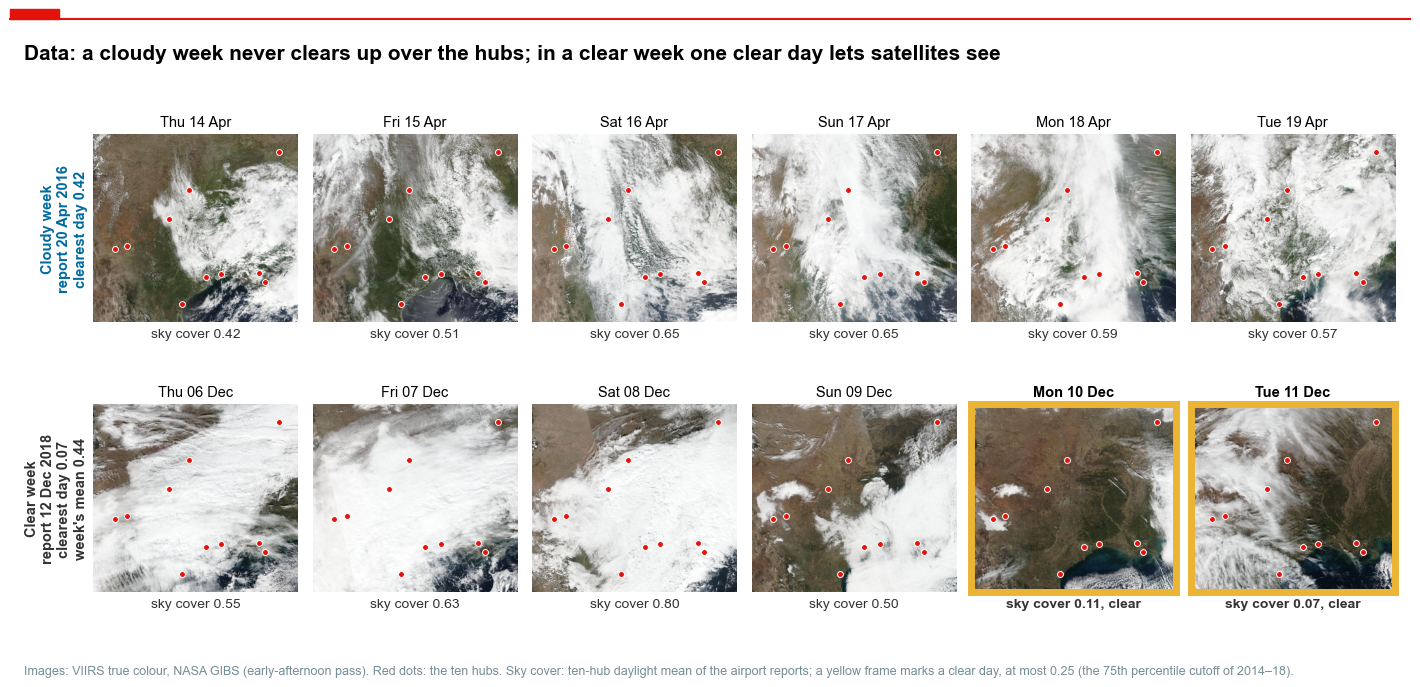

The weekly mean would label 50 of the 261 weeks of 2014–18 differently; cloudy weeks are most frequent in May (45% of its weeks in 2007–11 and 2014–18)


In [9]:
GIBS = "https://gibs.earthdata.nasa.gov/wms/epsg4326/best/wms.cgi"  # NASA's free satellite imagery service
MAP_BOX = (-105.0, 26.5, -87.5, 40.0)  # west, south, east, north: the ten hubs with a margin
FILMSTRIP = {  # reports of 2016-18 (VIIRS images start in November 2015)
    "Cloudy week": "2016-04-20",  # the week whose clearest day was the cloudiest
    "Clear week": "2018-12-12",  # the clearest single day among the weeks that the weekly mean calls cloudy
}


def satellite_image(day):
    '''True-colour VIIRS image (NASA GIBS) of the hub region on one day, cached in data/raw/gibs/.'''
    name = os.path.join("gibs", f"viirs_{day:%Y-%m-%d}.jpg")
    query = {"SERVICE": "WMS", "REQUEST": "GetMap", "VERSION": "1.1.1", "SRS": "EPSG:4326", "STYLES": "",
             "LAYERS": "VIIRS_SNPP_CorrectedReflectance_TrueColor", "FORMAT": "image/jpeg", "WIDTH": 700,
             "HEIGHT": 540, "BBOX": ",".join(map(str, MAP_BOX)), "TIME": f"{day:%Y-%m-%d}"}
    SOURCES[name] = f"{GIBS}?{urllib.parse.urlencode(query)}"
    return plt.imread(fetch(name))


cutoff = base["threshold"].iloc[0]
hub_lat, hub_lon = np.array([(lat, lon) for _, lat, lon in config.HUBS.values()]).T
fig, axes = plt.subplots(2, 6, figsize=(14, 6.3))
for row, (label, report) in enumerate(FILMSTRIP.items()):
    week = reports.loc[reports["release"] == pd.Timestamp(report)].iloc[0]
    days = pd.date_range(week["inventory_date"] - pd.Timedelta(days=1), week["release"] - pd.Timedelta(days=1))
    for ax, day in zip(axes[row], days):
        clear = daily_cloud[day] <= cutoff
        ax.imshow(satellite_image(day), extent=(MAP_BOX[0], MAP_BOX[2], MAP_BOX[1], MAP_BOX[3]))
        ax.set_aspect(1 / np.cos(np.radians(33)))  # true distances at the hubs' latitude
        ax.scatter(hub_lon, hub_lat, s=18, color=ECONOMIST_RED, edgecolor="white", lw=0.7, zorder=3)
        ax.set_title(f"{day:%a %d %b}", loc="center", fontsize=10.5, fontweight="bold" if clear else "normal")
        ax.set_xlabel(f"sky cover {daily_cloud[day]:.2f}" + (", clear" if clear else ""), fontsize=10,
                      fontweight="bold" if clear else "normal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():  # a yellow frame marks a clear day
            spine.set_visible(clear)
            spine.set_color(CLEAR)
            spine.set_linewidth(5)
    extra = "" if row == 0 else f"\nweek's mean {week['cloud_mean']:.2f}"
    axes[row, 0].set_ylabel(f"{label}\nreport {week['release']:%d %b %Y}\nclearest day {week['cloud_min']:.2f}{extra}",
                            fontsize=10.5, fontweight="bold", color=CLOUDY if row == 0 else DARK)
fig.text(0.01, -0.02, f"Images: VIIRS true colour, NASA GIBS (early-afternoon pass). Red dots: the ten hubs. Sky cover: "
         f"ten-hub daylight mean of the airport reports; a yellow frame marks a clear day, at most {cutoff:.2f} "
         f"(the 75th percentile cutoff of 2014–18).", fontsize=9, color=GREY)
show("Data: a cloudy week never clears up over the hubs; in a clear week one clear day lets satellites see",
     save="a1_cloudy_vs_clear_week")
pooled = pd.concat([pre, base])
season = pooled.groupby(pooled["release"].dt.month)["cloudy"].mean()
old_rule = base["cloud_mean"] > base["cloud_mean"].quantile(CLOUDY_QUANTILE)
print(f"The weekly mean would label {(old_rule != (base['cloudy'] == 1)).sum()} of the {len(base)} weeks of 2014–18 "
      f"differently; cloudy weeks are most frequent in {pd.Timestamp(2001, season.idxmax(), 1):%B} "
      f"({season.max():.0%} of its weeks in 2007–11 and 2014–18)")

**Comments – 1.3**
* **One clear day is enough:** in the April 2016 week the hubs stay under cloud from Thursday to Tuesday (clearest day 0.42). In the December 2018 week clouds cover them for four days, but Monday and Tuesday are clear (0.11 and 0.07), so satellites could count the oil before the Wednesday report.
* **The rule matters:** by its mean (0.44) the December week looks cloudy; the weekly mean, which our `03_cloudiness.py` used until now, labels 50 of the 261 weeks of 2014–18 differently.
* **Clouds are seasonal:** cloudy weeks are most frequent in May (45% of May weeks), so Task #4 compares weeks within the same quarter and 3.1 days within the same month.

### 1.4 Table 1: summary statistics, 2014–18
The return is USO's from 10:30 to 11:00 a.m. on report days; the paper's is the WTI futures' over the same half hour.

In [10]:
PAPER_TABLE_1 = {  # paper, Table 1 (2014-18): observations, mean, median, standard deviation
    "Daily cloudiness": (1826, 0.35, 0.33, 0.16),
    "Oil inventory (million barrels)": (261, 434.37, 438.45, 57.56),
    "Return 10:30–11:00 on report days (%)": (261, -0.08, -0.03, 1.13),
    "Implied oil variance, (OVX/100)²": (1258, 0.13, 0.10, 0.10),
}
first, last = PERIODS["2014–18"]
in_base = reports[reports["release"].between(first, last)]
ours = {
    "Daily cloudiness": daily_cloud[first:last],
    "Oil inventory (million barrels)": in_base["stocks"],
    "Return 10:30–11:00 on report days (%)": in_base["ret"].dropna(),
    "Implied oil variance, (OVX/100)²": (ovx[first:last] / 100) ** 2,
}
STATISTICS = ["Obs.", "Mean", "Median", "St. dev."]
table_1 = pd.concat({
    "Ours": pd.DataFrame({name: [series.count(), series.mean(), series.median(), series.std()]
                          for name, series in ours.items()}, index=STATISTICS).T,
    "Paper": pd.DataFrame(PAPER_TABLE_1, index=STATISTICS).T,
}, axis=1)
table_1.style.format("{:,.2f}").format("{:,.0f}", subset=[("Ours", "Obs."), ("Paper", "Obs.")])

In [11]:
cloudy_size, clear_size = (base.loc[base["cloudy"] == flag, "x"].abs() for flag in (1, 0))
print(f"Exclusion check: the absolute surprise is {cloudy_size.mean():.2f} SD in cloudy and {clear_size.mean():.2f} SD "
      f"in clear weeks (t-test p = {ttest_ind(cloudy_size, clear_size, equal_var=False).pvalue:.2f})")

Exclusion check: the absolute surprise is 0.73 SD in cloudy and 0.82 SD in clear weeks (t-test p = 0.28)


**Comments – Task #1**
* **Our data match the paper's:** 261 reports with mean stocks of 433.95 million barrels (paper 434.37), and 1,258 OVX days whose implied variance has the paper's mean, median and SD (0.13, 0.10, 0.10). USO's 10:30 to 11:00 a.m. return is a little less noisy than the futures' (SD 0.99% against 1.13%). Our daily cloudiness is a little lower (mean 0.33 against 0.35), partly because `04_build_long_sample.py` picks each hub's airport anew every year: with one fixed airport per hub (`03_cloudiness.py`) the mean is 0.34 (Task #4).
* **Release dates:** the rule finds 745 of the 751 archived dates; the six misses are special cases (Hurricane Sandy, the 2013 shutdown, a national day of mourning in 2018, the 2021 inauguration, two year ends), so the 2007–11 dates, which rest on the rule, should be right. All 261 reports of 2014–18 have a USO return.
* **Clouds do not predict the size of the news:** the absolute surprise is 0.73 SD in cloudy and 0.82 SD in clear weeks (p = 0.28), in line with the paper's Table IA-1.

## Task #2 – Main result: the price impact of the EIA report in clear and cloudy weeks
### 2.1 Tables 2 and 3: clear against cloudy weeks
Eq. (1) of the paper: ret = α + β_clear · ΔInv · Clear + β_cloudy · ΔInv · Cloudy + ε, with ΔInv the surprise scaled to unit standard deviation and ret USO's return over the paper's windows around the 10:30 a.m. report. Like the paper we report bootstrap p-values (5,000 draws of weeks). The placebos of Table 3: the pre-period 2007–11, the window two hours later (12:30 to 1:00 p.m.), and 10:30 to 11:00 a.m. on the other trading days of the report's week.

In [12]:
BOOT_DRAWS = 5_000  # bootstrap draws behind every p-value and interval
SEED = 20598  # every bootstrap starts from this seed, so reruns give the same numbers


def ols(y, X):
    '''OLS coefficients (k x m) of y (n x m) on X (n x k); also for stacks of samples along a first axis.'''
    Xt = np.swapaxes(X, -1, -2)
    return np.linalg.solve(Xt @ X, Xt @ y)


def bootstrap_draws(y, X, groups=None):
    '''Coefficients of BOOT_DRAWS samples of rows drawn with replacement; rows of one group stay together.'''
    rng = np.random.default_rng(SEED)
    if groups is None:
        rows = rng.integers(0, len(y), size=(BOOT_DRAWS, len(y)))
        return ols(y[rows], X[rows])
    members = [np.flatnonzero(groups == group) for group in pd.unique(groups)]
    picks = rng.integers(0, len(members), size=(BOOT_DRAWS, len(members)))
    return np.array([ols(y[rows], X[rows]) for rows in (np.concatenate([members[i] for i in pick]) for pick in picks)])


def p_value(draws):
    '''Two-sided bootstrap p-value: twice the share of draws on the far side of zero.'''
    return min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean()))


def regress(table, terms, outcome="ret", groups=None, controls=()):
    '''OLS of outcome on a constant, the named terms and controls. Returns estimate, bootstrap p-value and
    95% interval for each term and for "gap" (second term minus first), with R² and n in attrs.'''
    X = np.column_stack([np.ones(len(table)), *terms.values(), *(table[c] for c in controls)]).astype(float)
    y = table[[outcome]].to_numpy(float)
    beta = ols(y, X)[:, 0]
    draws = bootstrap_draws(y, X, groups)[:, :, 0]
    estimates = {name: (beta[i], draws[:, i]) for i, name in enumerate(terms, start=1)}
    if len(terms) == 2:
        estimates["gap"] = (beta[2] - beta[1], draws[:, 2] - draws[:, 1])
    result = pd.DataFrame({name: {"estimate": value, "p": p_value(d), "low": np.percentile(d, 2.5),
                                  "high": np.percentile(d, 97.5)} for name, (value, d) in estimates.items()}).T
    residuals = y[:, 0] - X @ beta
    result.attrs = {"r2": 1 - residuals.var() / y[:, 0].var(), "n": len(table)}
    return result


def reaction(sample, outcome="ret", groups=None, controls=()):
    '''Eq. (1): the clear and cloudy reactions to a 1 SD surprise, and their gap.'''
    terms = {"clear": sample["x"] * (1 - sample["cloudy"]), "cloudy": sample["x"] * sample["cloudy"]}
    return regress(sample, terms, outcome, groups, controls)


def with_window(sample, start, end):
    '''The sample with ret replaced by USO's return from start to end on the report day.'''
    return sample.assign(ret=sample["release"].map(window_returns(start, end))).dropna(subset=["ret"])


def other_days(sample, window=MAIN_WINDOW):
    '''Window returns on the other trading days of each report's Monday-to-Friday week, with the week's surprise.'''
    returns, rows = window_returns(*window), []
    for week in sample.itertuples():
        monday = week.release - pd.Timedelta(days=week.release.dayofweek)
        days = returns.loc[monday: monday + pd.Timedelta(days=4)].drop(week.release, errors="ignore")
        rows += [{"release": week.release, "x": week.x, "cloudy": week.cloudy, "ret": ret} for ret in days]
    return pd.DataFrame(rows)


def stars(p):
    '''Significance stars at the 10%, 5% and 1% levels, as in the paper.'''
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


def paper_style(result, rows=("β clear", "β cloudy", "Difference")):
    '''A column in the format of the paper's tables: estimate with stars and (p-value), R², observations.'''
    cells = [minus_sign(f"{value:.2f}{stars(p)} ({p:.2f})") for value, p in zip(result["estimate"], result["p"])]
    return pd.Series([*cells, f"{result.attrs['r2']:.2f}", f"{result.attrs['n']:,}"], index=[*rows, "R²", "Observations"])


def paper_column(numbers, rows=("β clear", "β cloudy", "Difference")):
    '''The paper's published column: ((estimate, p) for each row, R², observations).'''
    *estimates, r2, n = numbers
    cells = [minus_sign(f"{value:.2f}{stars(p)} ({p:.2f})") for value, p in estimates]
    return pd.Series([*cells, f"{r2:.2f}", f"{n:,}"], index=[*rows, "R²", "Observations"])


PAPER_TABLES_2_3 = {  # (estimate, p) for clear, cloudy, difference; R²; observations; 10:30-11:00 a.m. unless noted
    "2014–18": ((-0.05, 0.50), (-0.51, 0.00), (-0.46, 0.00), 0.05, 261),
    "2007–11": ((-0.43, 0.00), (-0.31, 0.02), (0.12, 0.43), 0.12, 261),
    "12:30": ((0.03, 0.35), (0.01, 0.75), (-0.02, 0.71), 0.01, 261),  # 2014-18, 12:30 to 1:00 p.m.
    "no report": ((-0.01, 0.69), (0.03, 0.33), (0.03, 0.31), 0.00, 992),  # 2014-18, days without a report
}
PAPER_WIDER = {  # Table 2, 2014-18, the wider windows
    ("09:30", "11:30"): ((-0.07, 0.38), (-0.55, 0.00), (-0.48, 0.01), 0.04, 261),
    ("09:45", "11:15"): ((-0.06, 0.46), (-0.52, 0.01), (-0.46, 0.01), 0.04, 261),
    ("10:00", "11:00"): ((-0.10, 0.18), (-0.55, 0.00), (-0.45, 0.01), 0.06, 261),
}
others = other_days(base)
results = {"2014–18": reaction(base), "2007–11": reaction(pre), "12:30": reaction(with_window(base, "12:30", "13:00")),
           "no report": reaction(others, groups=others["release"].to_numpy())}
table_2 = {("10:30–11:00", "Ours"): paper_style(results["2014–18"]),
           ("10:30–11:00", "Paper"): paper_column(PAPER_TABLES_2_3["2014–18"])}
for window, published in reversed(PAPER_WIDER.items()):
    label = "–".join(window)
    table_2[(label, "Ours")] = paper_style(reaction(with_window(base, *window)))
    table_2[(label, "Paper")] = paper_column(published)
pd.concat(table_2, axis=1)

10:30–11:00                      10:00–11:00  \
                        Ours            Paper            Ours   
β clear        −0.12* (0.07)     −0.05 (0.50)   −0.13* (0.09)   
β cloudy      −0.28** (0.02)  −0.51*** (0.00)  −0.29** (0.01)   
Difference      −0.16 (0.25)  −0.46*** (0.00)    −0.17 (0.24)   
R²                      0.03             0.05            0.03   
Observations             261              261             261   

                                   09:45–11:15                  \
                        Paper             Ours           Paper   
β clear          −0.10 (0.18)     −0.12 (0.13)    −0.06 (0.46)   
β cloudy      −0.55*** (0.00)  −0.48*** (0.00)  −0.52** (0.01)   
Difference     −0.45** (0.01)   −0.35** (0.04)  −0.46** (0.01)   
R²                       0.06             0.05            0.04   
Observations              261              261             261   

                  09:30–11:30                   
                         Ours            Paper  
β clear          −0.11 (0.22)     −0.07 (0.38)  
β cloudy      −0.53*** (0.00)  −0.55*** (0.00)  
Difference     −0.42** (0.02)   −0.48** (0.01)  
R²                       0.04             0.04  
Observations              261              261

In [13]:
pd.concat({
    ("Pre-period 2007–11", "Ours"): paper_style(results["2007–11"]),
    ("Pre-period 2007–11", "Paper"): paper_column(PAPER_TABLES_2_3["2007–11"]),
    ("12:30–13:00", "Ours"): paper_style(results["12:30"]),
    ("12:30–13:00", "Paper"): paper_column(PAPER_TABLES_2_3["12:30"]),
    ("Days without a report", "Ours"): paper_style(results["no report"]),
    ("Days without a report", "Paper"): paper_column(PAPER_TABLES_2_3["no report"]),
}, axis=1)

Pre-period 2007–11                    12:30–13:00                \
                           Ours            Paper          Ours         Paper   
β clear         −0.36*** (0.00)  −0.43*** (0.00)  0.06* (0.07)   0.03 (0.35)   
β cloudy        −0.32*** (0.01)   −0.31** (0.02)   0.00 (0.94)   0.01 (0.75)   
Difference          0.04 (0.80)      0.12 (0.43)  −0.06 (0.29)  −0.02 (0.71)   
R²                         0.11             0.12          0.02          0.01   
Observations                261              261           261           261   

             Days without a report                
                              Ours         Paper  
β clear               −0.01 (0.74)  −0.01 (0.69)  
β cloudy               0.01 (0.58)   0.03 (0.33)  
Difference             0.02 (0.53)   0.03 (0.31)  
R²                            0.00          0.00  
Observations                   998           992

10:30–11:00 returns in 2014–18: SD 0.99% (paper 1.13%), so a 5% test finds the paper's gap with 90% probability (paper 81%); HC1 instead of bootstrap p-values for the gap: 0.29 (2014–18), 0.79 (2007–11)


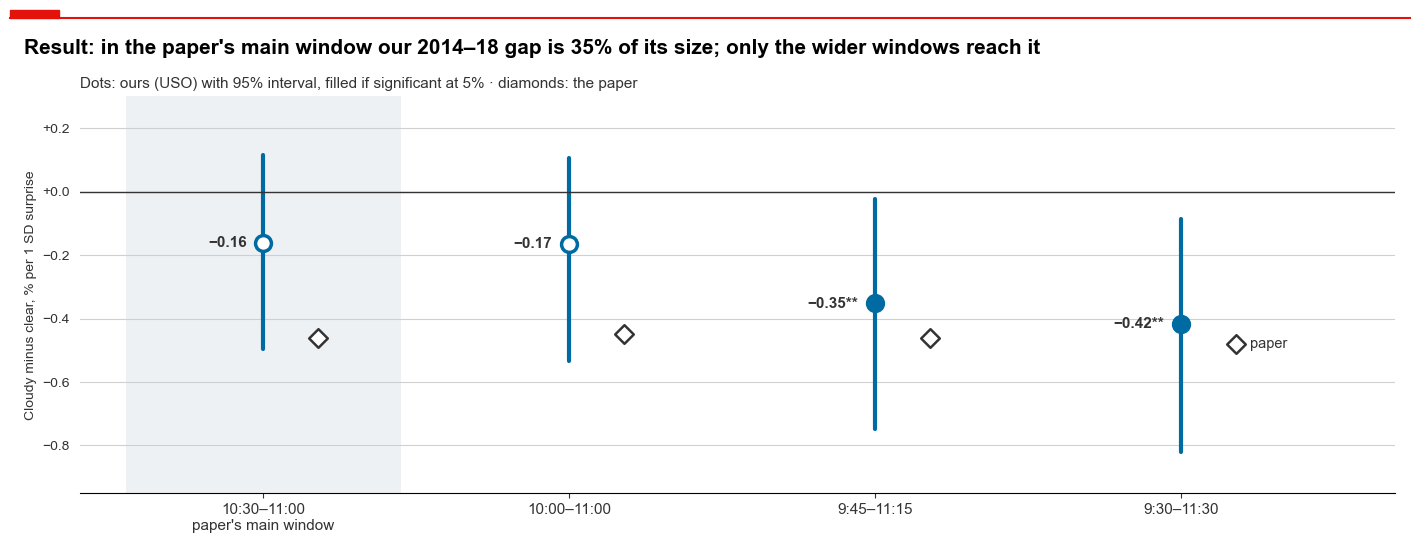

In [14]:
def robust_gap_p(sample):
    '''p-value of the cloudy minus clear gap with heteroskedasticity-robust (HC1) errors (paper, Table IA-2).'''
    X = sm.add_constant(pd.DataFrame({"clear": sample["x"] * (1 - sample["cloudy"]),
                                      "cloudy": sample["x"] * sample["cloudy"]}))
    return float(sm.OLS(sample["ret"], X).fit(cov_type="HC1").t_test("cloudy - clear = 0").pvalue)


PAPER_GAP = -0.46  # Table 2, 10:30-11:00 a.m.: cloudy minus clear reaction per 1 SD surprise (%)
PAPER_WINDOW_SD = 1.13  # Table 1: standard deviation of the 10:30-11:00 a.m. return (%)


def power(sd, n_clear, n_cloudy, gap=PAPER_GAP):
    '''Chance that a two-sided 5% test finds a true gap, with return noise of standard deviation sd.'''
    z = abs(gap) / (sd * np.sqrt(1 / n_clear + 1 / n_cloudy))
    return norm.cdf(z - Z_95) + norm.cdf(-z - Z_95)


n_cloudy = int(base["cloudy"].sum())
n_clear = len(base) - n_cloudy
print(f"10:30–11:00 returns in 2014–18: SD {base['ret'].std():.2f}% (paper {PAPER_WINDOW_SD:.2f}%), so a 5% test finds "
      f"the paper's gap with {power(base['ret'].std(), n_clear, n_cloudy):.0%} probability (paper "
      f"{power(PAPER_WINDOW_SD, n_clear, n_cloudy):.0%}); HC1 instead of bootstrap p-values for the gap: "
      f"{robust_gap_p(base):.2f} (2014–18), {robust_gap_p(pre):.2f} (2007–11)")

WINDOWS = [MAIN_WINDOW, *reversed(PAPER_WIDER)]  # the paper's Table 2 columns, narrow to wide
window_gaps = {window: (results["2014–18"] if window == MAIN_WINDOW else reaction(with_window(base, *window))).loc["gap"]
               for window in WINDOWS}
paper_gaps = {MAIN_WINDOW: PAPER_TABLES_2_3["2014–18"][2][0], **{window: v[2][0] for window, v in PAPER_WIDER.items()}}

fig, ax = plt.subplots(figsize=(14, 5.2))
ax.axvspan(-0.45, 0.45, color=LIGHT_GREY, alpha=0.3, lw=0)  # the paper's main window
for i, window in enumerate(WINDOWS):
    gap = window_gaps[window]
    filled = gap["high"] < 0 or gap["low"] > 0  # a filled dot is significant at 5%
    ax.plot([i, i], [gap["low"], gap["high"]], color=GAP, lw=3, solid_capstyle="round")
    ax.scatter(i, gap["estimate"], s=130, color=GAP if filled else "white", edgecolor=GAP, lw=2.5, zorder=3)
    annotate(ax, minus_sign(f"{gap['estimate']:+.2f}{stars(gap['p'])}"), (i, gap["estimate"]), offset=(-12, 0),
             color=DARK, fontweight="bold", fontsize=11)
    ax.scatter(i + 0.18, paper_gaps[window], s=90, marker="D", facecolor="white", edgecolor=PAPER, lw=1.8, zorder=4)
annotate(ax, "paper", (len(WINDOWS) - 1 + 0.18, paper_gaps[WINDOWS[-1]]), offset=(10, 0), color=PAPER, fontsize=10.5)
ax.set_title("Dots: ours (USO) with 95% interval, filled if significant at 5% · diamonds: the paper", fontsize=11,
             fontweight="normal", color=DARK)
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(range(len(WINDOWS)), [f"{start.lstrip('0')}–{end}" + ("\npaper's main window" if i == 0 else "")
                                    for i, (start, end) in enumerate(WINDOWS)], fontsize=11)
ax.set_xlim(-0.6, len(WINDOWS) - 0.3)
ax.set_ylim(-0.95, 0.3)
ax.yaxis.set_major_formatter(SIGNED)
ax.set_ylabel("Cloudy minus clear, % per 1 SD surprise")
share = window_gaps[MAIN_WINDOW]["estimate"] / paper_gaps[MAIN_WINDOW]
show(f"Result: in the paper's main window our 2014–18 gap is {share:.0%} of its size; only the wider windows reach it", save="a2_gap_by_window")

**Comments – 2.1**
* **Smaller in the paper's main window:** from 10:30 to 11:00 a.m. a 1 SD surprise moves USO by −0.28% in cloudy and −0.12% in clear weeks (paper −0.51% and −0.05%), a gap of −0.16 (p = 0.25) against the paper's −0.46. Our returns are as precise as the paper's (90% power against its gap), so lack of power no longer explains the difference; still, our interval (−0.50 to +0.12) just includes the paper's estimate.
* **The paper's size in its wider windows:** from 9:45 to 11:15 the gap is −0.35 (p = 0.04), from 9:30 to 11:30 −0.42 (p = 0.02; paper −0.48). In our data the cloudy weeks' reaction arrives later (2.2).
* **All three placebos hold:** the gap is +0.04 in 2007–11 (paper +0.12), −0.06 from 12:30 to 1:00 p.m. (p = 0.29; paper −0.02) and +0.02 on days without a report (p = 0.53; paper +0.03). The pre-period reactions (−0.36% and −0.32%) are the paper's (−0.43% and −0.31%), so USO tracks the futures well.

### 2.2 Figure 5: when does the price move?
The paper widens the return window in 15-minute steps from 9:30 a.m. to 12:30 p.m. We do the same with USO and draw the paper's lines on top, read off its published figure (about ±0.01; at 11:30 they match Tables 2 and 3). If clouds matter, cloudy weeks fall right after the 10:30 report and clear weeks barely move.

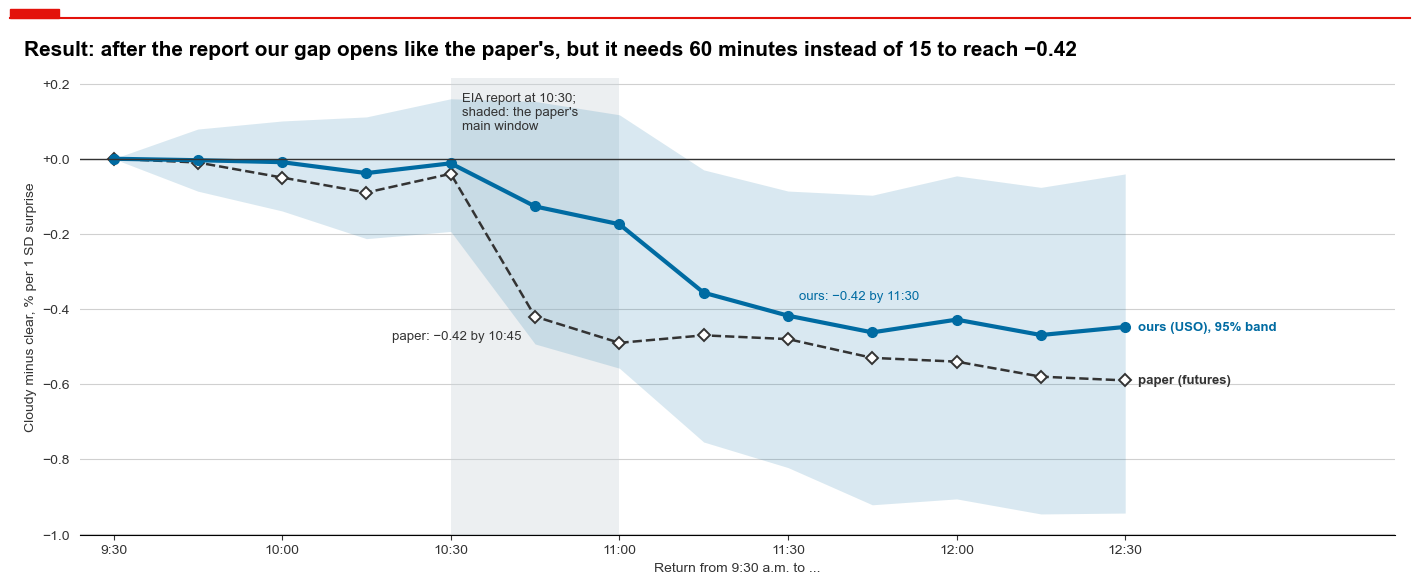

2014–18, ours (paper) at 10:45 and 12:30: clear −0.18 (−0.17) and −0.12 (−0.06), cloudy −0.31 (−0.58) and −0.57 (−0.65); gap by 12:30 −0.45 [−0.94, −0.04] (paper −0.59); before the report −0.01
2007–11, ours (paper) at 10:45 and 12:30: clear −0.42 (−0.55) and −0.46 (−0.52), cloudy −0.49 (−0.48) and −0.40 (−0.40); gap by 12:30 +0.06 [−0.31, +0.41] (paper −0.05); before the report −0.15


In [15]:
# The paper's Figure 5, read off the published image (about ±0.01; at 11:30 it matches Tables 2 and 3): slopes for
# returns from 9:30 a.m. to each quarter hour until 12:30, their gap (cloudy minus clear) and its 95% bootstrap band.
# The published figure's last pre-period gap (−0.05) differs from its cloudy minus clear (+0.12); we plot both as published.
PAPER_FIGURE_5 = {
    "2014–18": {"clear": [0, .01, .01, 0, -.04, -.17, -.09, -.05, -.07, -.06, -.08, -.06, -.06],
                "cloudy": [0, 0, -.04, -.09, -.08, -.58, -.58, -.52, -.55, -.59, -.63, -.65, -.65],
                "gap": [0, -.01, -.05, -.09, -.04, -.42, -.49, -.47, -.48, -.53, -.54, -.58, -.59],
                "low": [0, -.09, -.16, -.21, -.16, -.68, -.77, -.80, -.81, -.89, -.90, -.97, -.99],
                "high": [0, .06, .05, .03, .08, -.17, -.21, -.18, -.20, -.19, -.22, -.25, -.24]},
    "2007–11": {"clear": [0, -.07, -.03, -.05, -.11, -.55, -.53, -.54, -.51, -.51, -.54, -.57, -.52],
                "cloudy": [0, .05, -.02, -.09, -.19, -.48, -.50, -.54, -.48, -.43, -.47, -.45, -.40],
                "gap": [0, .12, .01, -.05, -.09, .07, .03, 0, .03, .08, .07, .12, -.05],
                "low": [0, .03, -.09, -.18, -.24, -.19, -.25, -.30, -.30, -.22, -.26, -.19, -.32],
                "high": [0, .19, .10, .08, .07, .30, .31, .30, .36, .39, .37, .45, .39]}}
MINUTES = np.arange(0, 181, 15)  # end of each return window, in minutes after 9:30
HORIZONS = [f"{(OPEN + m) // 60:02d}:{(OPEN + m) % 60:02d}" for m in MINUTES]  # 09:30, 09:45, ..., 12:30
REPORT_MINUTE = 61  # the report comes out at 10:30, just after the last trade of our 10:30 price


def figure_5(sample):
    '''β clear, β cloudy and their gap for returns from 9:30 a.m. to each horizon, with 95% bootstrap bands
    (the same draws of weeks for every horizon).'''
    y = np.column_stack([sample["release"].map(window_returns("09:30", end)).to_numpy() for end in HORIZONS])
    complete = ~np.isnan(y).any(axis=1)
    sample, y = sample[complete], y[complete]
    X = np.column_stack([np.ones(len(sample)), sample["x"] * (1 - sample["cloudy"]), sample["x"] * sample["cloudy"]])
    beta, draws = ols(y, X), bootstrap_draws(y, X)
    lines = {"clear": (beta[1], draws[:, 1]), "cloudy": (beta[2], draws[:, 2]),
             "gap": (beta[2] - beta[1], draws[:, 2] - draws[:, 1])}
    return {name: pd.DataFrame({"estimate": value, "low": np.percentile(d, 2.5, axis=0),
                                "high": np.percentile(d, 97.5, axis=0)}, index=HORIZONS)
            for name, (value, d) in lines.items()}


paths = {period: figure_5(sample) for period, sample in [("2014–18", base), ("2007–11", pre)]}
ours, paper = paths["2014–18"]["gap"], pd.Series(PAPER_FIGURE_5["2014–18"]["gap"], index=HORIZONS)
first_paper = paper.loc["10:45"]  # the paper's gap 15 minutes after the report
catch_up = next(clock for clock in HORIZONS if clock > "10:30" and ours.loc[clock, "estimate"] <= first_paper + 0.01)
lag = int(MINUTES[HORIZONS.index(catch_up)] - MINUTES[HORIZONS.index("10:30")])

fig, ax = plt.subplots(figsize=(14, 5.6))
ax.axvspan(60, 90, color=LIGHT_GREY, alpha=0.35, lw=0)
ax.text(62, 0.97, "EIA report at 10:30;\nshaded: the paper's\nmain window", transform=ax.get_xaxis_transform(),
        va="top", fontsize=9.5, color=DARK)
ax.fill_between(MINUTES, ours["low"], ours["high"], color=GAP, alpha=0.15, lw=0)
ax.plot(MINUTES, paper, color=PAPER, lw=1.8, ls="--", marker="D", ms=6, mfc="white", mew=1.4)
ax.plot(MINUTES, ours["estimate"], color=GAP, lw=3, marker="o", ms=7)
annotate(ax, "paper (futures)", (MINUTES[-1], paper.iloc[-1]), color=PAPER, fontweight="bold")
annotate(ax, "ours (USO), 95% band", (MINUTES[-1], ours["estimate"].iloc[-1]), color=GAP, fontweight="bold")
annotate(ax, minus_sign(f"paper: {first_paper:+.2f} by 10:45"), (75, first_paper), offset=(-10, -14), color=PAPER)
annotate(ax, minus_sign(f"ours: {ours.loc[catch_up, 'estimate']:+.2f} by {catch_up}"),
         (MINUTES[HORIZONS.index(catch_up)], ours.loc[catch_up, "estimate"]), offset=(8, 14), color=GAP)
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(MINUTES[::2], [clock.lstrip("0") for clock in HORIZONS[::2]])
ax.set_xlim(-6, 228)
ax.yaxis.set_major_formatter(SIGNED)
ax.set_ylabel("Cloudy minus clear, % per 1 SD surprise")
ax.set_xlabel("Return from 9:30 a.m. to ...")
show(f"Result: after the report our gap opens like the paper's, but it needs {lag} minutes instead of 15 to reach "
     + minus_sign(f"{first_paper:+.2f}"), save="a3_timing_vs_paper")
for period, lines in paths.items():
    figure = PAPER_FIGURE_5[period]
    print(minus_sign(f"{period}, ours (paper) at 10:45 and 12:30: clear {lines['clear'].loc['10:45', 'estimate']:+.2f} "
                     f"({figure['clear'][5]:+.2f}) and {lines['clear'].loc['12:30', 'estimate']:+.2f} ({figure['clear'][-1]:+.2f}), "
                     f"cloudy {lines['cloudy'].loc['10:45', 'estimate']:+.2f} ({figure['cloudy'][5]:+.2f}) and "
                     f"{lines['cloudy'].loc['12:30', 'estimate']:+.2f} ({figure['cloudy'][-1]:+.2f}); gap by 12:30 "
                     f"{lines['gap'].loc['12:30', 'estimate']:+.2f} [{lines['gap'].loc['12:30', 'low']:+.2f}, "
                     f"{lines['gap'].loc['12:30', 'high']:+.2f}] (paper {figure['gap'][-1]:+.2f}); before the report "
                     f"{lines['gap'].loc['10:30', 'estimate']:+.2f}"))

**Comments – 2.2**
* **The same gap, an hour to build:** nothing moves before the report (gap −0.01 at 10:30). The paper's gap is −0.42 fifteen minutes later; ours is −0.13 at 10:45 and −0.17 at 11:00, and reaches −0.42 only at 11:30. By 12:30 it is −0.45, with a band (−0.94 to −0.04) that excludes zero, against the paper's −0.59.
* **Not a slow ETF:** clear weeks react within 15 minutes (−0.18 at 10:45; paper −0.17), and so do both kinds of weeks in 2007–11 (clear −0.42 and cloudy −0.49 at 10:45; paper −0.55 and −0.48). The delay is specific to our cloudy weeks of 2014–18, so for us the paper's choice of 10:30–11:00 as its main window matters.

## Task #3 – Mechanism: uncertainty and timing
### 3.1 Table 5: implied volatility after cloudy and clear days
The paper regresses the OVX-implied variance of day t+1 on a cloudy-day dummy of day t (a satellite's estimate of day t reaches the market on t+1), with bootstrap p-values that treat days as independent. But OVX is very persistent and clouds are seasonal, so we add Newey-West errors and compare days within the same calendar month, or within the same month of the same year.

In [16]:
OVX_LAGS = 20  # Newey-West lags, about a month of trading days
PAPER_TABLE_5 = {"2014–18": (0.128, 0.143, 0.015, 0.02, 1258), "2007–11": (0.199, 0.201, 0.002, 0.82, 1170)}
# clear mean, cloudy mean, difference, its bootstrap p-value, observations


def ovx_days(period):
    '''Daily implied variance (OVX/100)² with the cloudy dummy of the previous calendar day.'''
    first, last = PERIODS[period]
    variance = (ovx[first:last] / 100) ** 2
    cloud = daily_cloud.reindex(variance.index - pd.Timedelta(days=1)).to_numpy()
    days = pd.DataFrame({"variance": variance, "cloud": cloud}).dropna()
    days["cloudy"] = (days["cloud"] > daily_cloud[first:last].quantile(CLOUDY_QUANTILE)).astype(float)
    return days


def ovx_gap(days, within=None):
    '''Cloudy minus clear implied variance with its Newey-West standard error; within = "calendar month"
    or "year and month" compares only days that share it.'''
    variance, cloudy = days["variance"], days["cloudy"]
    if within:
        key = days.index.month if within == "calendar month" else days.index.to_period("M")
        variance = variance - variance.groupby(key).transform("mean")
        cloudy = cloudy - cloudy.groupby(key).transform("mean")
    X = cloudy.to_frame() if within else sm.add_constant(cloudy)
    fit = sm.OLS(variance, X).fit(cov_type="HAC", cov_kwds={"maxlags": OVX_LAGS})
    return fit.params["cloudy"], fit.bse["cloudy"]


SPECS_5 = {  # label: comparison passed to ovx_gap
    "All days (paper)": None, "Same calendar month": "calendar month", "Same year and month": "year and month"}
table_5, gaps_5 = {}, {}
for period in PERIODS:
    days = ovx_days(period)
    paper_test = regress(days, {"cloudy": days["cloudy"]}, outcome="variance")  # i.i.d. bootstrap, as the paper
    clear_mean = days.loc[days["cloudy"] == 0, "variance"].mean()
    gaps_5[period] = {label: ovx_gap(days, within) for label, within in SPECS_5.items()}
    nw = {label: 2 * norm.sf(abs(gap / se)) for label, (gap, se) in gaps_5[period].items()}
    table_5[(period, "Ours")] = pd.Series({
        "β clear": f"{clear_mean:.3f}", "β cloudy": f"{clear_mean + paper_test.loc['cloudy', 'estimate']:.3f}",
        "Difference (bootstrap p)": minus_sign(f"{paper_test.loc['cloudy', 'estimate']:.3f} ({paper_test.loc['cloudy', 'p']:.2f})"),
        "Difference (Newey-West p)": minus_sign(f"{gaps_5[period]['All days (paper)'][0]:.3f} ({nw['All days (paper)']:.2f})"),
        "Same calendar month (NW p)": minus_sign(f"{gaps_5[period]['Same calendar month'][0]:.3f} ({nw['Same calendar month']:.2f})"),
        "Same year and month (NW p)": minus_sign(f"{gaps_5[period]['Same year and month'][0]:.3f} ({nw['Same year and month']:.2f})"),
        "Observations": f"{len(days):,}"})
    if period in PAPER_TABLE_5:
        clear, cloudy, gap, p, n = PAPER_TABLE_5[period]
        table_5[(period, "Paper")] = pd.Series({"β clear": f"{clear:.3f}", "β cloudy": f"{cloudy:.3f}",
                                                "Difference (bootstrap p)": f"{gap:.3f} ({p:.2f})", "Observations": f"{n:,}"})
ROWS_5 = ["β clear", "β cloudy", "Difference (bootstrap p)", "Difference (Newey-West p)", "Same calendar month (NW p)",
          "Same year and month (NW p)", "Observations"]
pd.DataFrame(table_5).reindex(ROWS_5).fillna("")

2007–11                      2014–18  \
                                     Ours         Paper           Ours   
β clear                             0.199         0.199          0.128   
β cloudy                            0.201         0.201          0.144   
Difference (bootstrap p)     0.001 (0.91)  0.002 (0.82)   0.016 (0.02)   
Difference (Newey-West p)    0.001 (0.94)                 0.016 (0.15)   
Same calendar month (NW p)  −0.022 (0.19)                −0.007 (0.49)   
Same year and month (NW p)  −0.001 (0.83)                −0.003 (0.12)   
Observations                        1,172         1,170          1,258   

                                                2019–25  
                                   Paper           Ours  
β clear                            0.128          0.218  
β cloudy                           0.143          0.245  
Difference (bootstrap p)    0.015 (0.02)   0.027 (0.29)  
Difference (Newey-West p)                  0.027 (0.55)  
Same calendar month (NW p)                −0.010 (0.81)  
Same year and month (NW p)                −0.013 (0.39)  
Observations                       1,258          1,675

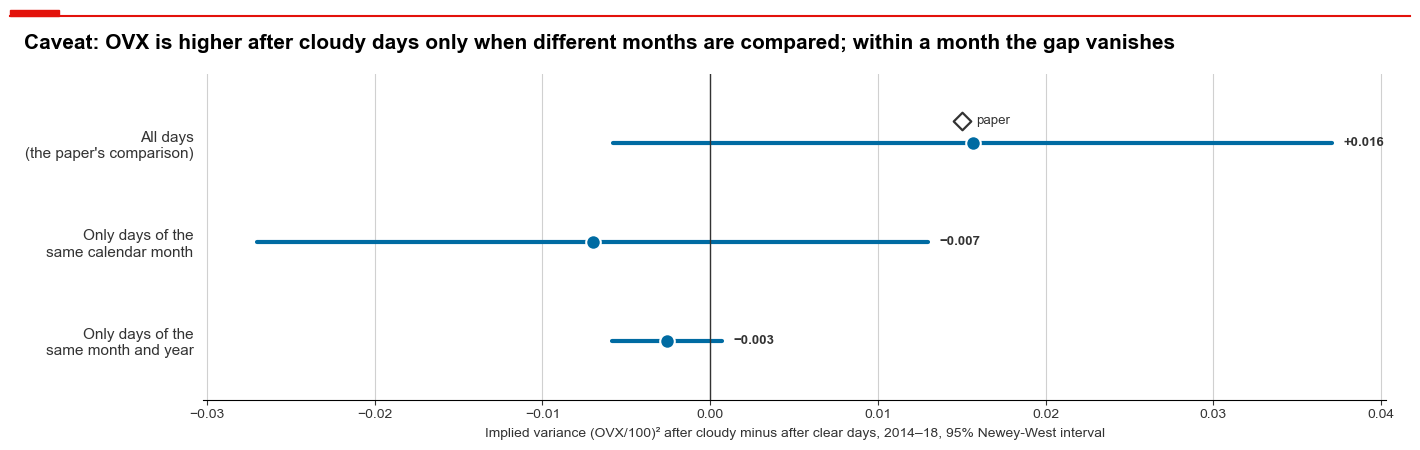

Jan–Mar 2015: 43% of days after a cloudy day and implied variance 0.30, against 24% and 0.12 in the other months
Monthly correlation of the cloudy share with implied variance: 0.19 (2014–18), −0.01 (2007–11); within a month of 2014–18, OVX is higher after cloudy days in 23 of 53 months


In [17]:
CRASH_MONTHS = pd.period_range("2015-01", "2015-03", freq="M")  # oil price crash in a cloudy winter
months = {}
for period in ("2014–18", "2007–11"):
    days = ovx_days(period)
    months[period] = days.groupby(days.index.to_period("M")).agg(cloudy_share=("cloudy", "mean"),
                                                                 variance=("variance", "mean"))
correlation = {period: table["cloudy_share"].corr(table["variance"]) for period, table in months.items()}
crash = months["2014–18"].index.isin(CRASH_MONTHS)

ROW_LABELS_5 = {"All days (paper)": "All days\n(the paper's comparison)", "Same calendar month": "Only days of the\nsame calendar month",
                "Same year and month": "Only days of the\nsame month and year"}
fig, ax = plt.subplots(figsize=(14, 4.3))
for row, (label, (gap, se)) in enumerate(gaps_5["2014–18"].items()):
    y = len(ROW_LABELS_5) - 1 - row  # the paper's comparison on top
    ax.plot([gap - Z_95 * se, gap + Z_95 * se], [y, y], color=GAP, lw=3, solid_capstyle="round")
    ax.scatter(gap, y, color=GAP, s=110, zorder=3, edgecolor="white", lw=1.5)
    annotate(ax, minus_sign(f"{gap:+.3f}"), (gap + Z_95 * se, y), offset=(8, 0), color=DARK, fontweight="bold")
ax.scatter(PAPER_TABLE_5["2014–18"][2], len(ROW_LABELS_5) - 1 + 0.22, marker="D", s=80, facecolor="white",
           edgecolor=PAPER, lw=1.6, zorder=4)
annotate(ax, "paper", (PAPER_TABLE_5["2014–18"][2], len(ROW_LABELS_5) - 1 + 0.22), offset=(10, 0), color=PAPER)
ax.axvline(0, color=DARK, lw=1)
ax.set_yticks(range(len(ROW_LABELS_5)), list(ROW_LABELS_5.values())[::-1], fontsize=11)
ax.set_ylim(-0.6, len(ROW_LABELS_5) - 0.3)
ax.set_xlabel("Implied variance (OVX/100)² after cloudy minus after clear days, 2014–18, 95% Newey-West interval")
vertical_grid(ax)
show("Caveat: OVX is higher after cloudy days only when different months are compared; within a month the gap vanishes")
days = ovx_days("2014–18")
by_month = days.groupby([days.index.to_period("M"), "cloudy"])["variance"].mean().unstack().dropna()
print(f"Jan–Mar 2015: {months['2014–18'].loc[crash, 'cloudy_share'].mean():.0%} of days after a cloudy day and implied "
      f"variance {months['2014–18'].loc[crash, 'variance'].mean():.2f}, against "
      f"{months['2014–18'].loc[~crash, 'cloudy_share'].mean():.0%} and {months['2014–18'].loc[~crash, 'variance'].mean():.2f} in the other months")
print(minus_sign(f"Monthly correlation of the cloudy share with implied variance: {correlation['2014–18']:.2f} (2014–18), "
                 f"{correlation['2007–11']:.2f} (2007–11); within a month of 2014–18, OVX is higher after cloudy days "
                 f"in {(by_month[1.0] > by_month[0.0]).sum()} of {len(by_month)} months"))

**Comments – 3.1**
* **An exact replication:** after clear days the implied variance averages 0.128 and after cloudy days 0.144 (paper: 0.128 and 0.143), with the same bootstrap p-value of 0.02; in 2007–11 both are 0.199 and 0.201, as in the paper.
* **But the significance is not robust:** with Newey-West errors the 2014–18 gap has p = 0.15. Within the same calendar month it turns negative (−0.007), within the same month of the same year it is −0.003 (p = 0.12), and OVX is higher after cloudy days in only 23 of 53 months.
* **Where the paper's gap comes from:** across months, cloudier months were more volatile (correlation 0.19), above all the oil price crash of January to March 2015, a cloudy winter; in 2007–11 the correlation is −0.01. So a cloudy day does not raise uncertainty on the next day. Out of sample the gap is +0.027 (Newey-West p = 0.55), with a wide interval: OVX reached 325 in April 2020.

### 3.2 Table 6: does the price move after the first clear day?
In clear weeks the surprise should enter the price on the first trading day after the first clear day, when the satellite estimate is published. We use the trading days from the inventory Friday to the day before the report, each from its opening trade to the next day's (the paper: 9:00 to 9:00 a.m. in the round-the-clock futures market), so no return contains the report; we match the paper's columns without the announcement day.

In [18]:
PAPER_TABLE_6 = {  # paper, Table 6, without the announcement day: (estimate, p) first clear, other, difference; R²; n
    "2014–18": ((-0.20, 0.10), (-0.08, 0.34), (-0.12, 0.39), 0.00, 753),
    "2007–11": ((-0.06, 0.66), (0.05, 0.54), (-0.11, 0.47), 0.00, 707),
}


def first_clear_days(sample):
    '''Open-to-open returns of the trading days from the inventory Friday to the day before the report in clear weeks,
    flagged when the day is the first trading day after the week's first clear day.'''
    rows = []
    for week in sample[sample["cloudy"] == 0].itertuples():
        window = daily_cloud.loc[week.inventory_date - pd.Timedelta(days=1): week.release - pd.Timedelta(days=1)]
        first_clear = window[window <= week.threshold].index[0]
        days = daily_returns.loc[week.inventory_date: week.release - pd.Timedelta(days=1)]
        news_day = days.index[days.index > first_clear]  # the estimate of a day comes out the next morning
        rows += [{"release": week.release, "x": week.x, "ret": ret,
                  "first_clear": float(len(news_day) > 0 and day == news_day[0])} for day, ret in days.items()]
    return pd.DataFrame(rows)


results_6 = {}
for period in PERIODS:
    days = first_clear_days(weeks_of(period))
    terms = {"other": days["x"] * (1 - days["first_clear"]), "first clear": days["x"] * days["first_clear"]}
    results_6[period] = regress(days, terms, groups=days["release"].to_numpy())
ROWS_6 = ("β other days", "β first clear", "Difference")
pd.concat({
    ("2014–18", "Ours"): paper_style(results_6["2014–18"], ROWS_6),
    ("2014–18", "Paper"): paper_column([PAPER_TABLE_6["2014–18"][i] for i in (1, 0, 2)] + list(PAPER_TABLE_6["2014–18"][3:]), ROWS_6),
    ("2007–11", "Ours"): paper_style(results_6["2007–11"], ROWS_6),
    ("2007–11", "Paper"): paper_column([PAPER_TABLE_6["2007–11"][i] for i in (1, 0, 2)] + list(PAPER_TABLE_6["2007–11"][3:]), ROWS_6),
    ("2019–25", "Ours"): paper_style(results_6["2019–25"], ROWS_6),
}, axis=1)

2014–18                    2007–11                \
                       Ours         Paper         Ours         Paper   
β other days   −0.11 (0.23)  −0.08 (0.34)  0.05 (0.66)   0.05 (0.54)   
β first clear  −0.10 (0.49)  −0.20 (0.10)  0.06 (0.80)  −0.06 (0.66)   
Difference      0.00 (0.97)  −0.12 (0.39)  0.01 (0.98)  −0.11 (0.47)   
R²                     0.00          0.00         0.00          0.00   
Observations            589           753          588           707   

                      2019–25  
                         Ours  
β other days   −0.25** (0.04)  
β first clear     0.03 (0.83)  
Difference        0.28 (0.17)  
R²                       0.01  
Observations              781

**Comments – 3.2**
* **No trace of the first clear day:** in 2014–18 a 1 SD surprise moves USO by −0.10% on the first trading day after the first clear day and by −0.11% on the other days before the report (paper −0.20% and −0.08%), a gap of 0.00 (p = 0.97; paper −0.12, p = 0.39). Neither the paper's nor our evidence shows the information entering the price on that day.
* **Pre-period and after 2018:** +0.01 (p = 0.98; paper −0.11) and +0.28 (p = 0.17).

## Task #4 – Robustness of the main result
The Internet Appendix (Tables IA-2 and IA-3) varies the cutoff, the expectation model, the daylight hours and treats outliers. We add the week's mean instead of its least cloudy day, a window without the Thursday, one fixed airport per hub, and weeks without tropical storms: storms both cloud the Gulf hubs and disrupt imports and refineries, the clearest threat to the exclusion restriction.

In [19]:
STORM_KM = 300  # a tropical storm or hurricane this close to a hub makes a storm day
HURDAT_FILE = os.path.join("data", "raw", "hurdat2.txt")  # NHC best tracks (nhc.noaa.gov/data/#hurdat), in our data folder


def storm_days():
    '''Days on which a tropical storm or hurricane (HURDAT2 best track) passes within STORM_KM of a hub.'''
    fixes = []
    with open(HURDAT_FILE) as file:
        for line in file:
            parts = [part.strip() for part in line.split(",")]
            if parts[0].isdigit() and parts[0] >= "2006" and parts[3] in ("TS", "HU"):
                lat = float(parts[4][:-1]) * (1 if parts[4][-1] == "N" else -1)
                lon = float(parts[5][:-1]) * (-1 if parts[5][-1] == "W" else 1)
                fixes.append((pd.Timestamp(parts[0]), lat, lon))
    fixes = pd.DataFrame(fixes, columns=["day", "lat", "lon"])
    hubs = np.radians([[lat, lon] for _, lat, lon in config.HUBS.values()])
    lat, lon = np.radians(fixes[["lat"]].to_numpy()), np.radians(fixes[["lon"]].to_numpy())
    km = 6371 * 2 * np.arcsin(np.sqrt(np.sin((hubs[:, 0] - lat) / 2) ** 2
                                      + np.cos(lat) * np.cos(hubs[:, 0]) * np.sin((hubs[:, 1] - lon) / 2) ** 2))
    return pd.DatetimeIndex(fixes.loc[(km < STORM_KM).any(axis=1), "day"].unique())


storms = storm_days()
reports["storm"] = [storms[(storms >= inventory - pd.Timedelta(days=1)) & (storms < release)].size > 0
                    for inventory, release in zip(reports["inventory_date"], reports["release"])]
reports["cloud_min_from_friday"] = weekly_cloudiness(daily_cloud, first_day=0)
for hours in [(9, 15), (10, 14)]:
    reports[f"cloud_min_{hours[0]}_{hours[1]}"] = weekly_cloudiness(daily_cloudiness(hours))
change = 100 * reports["stocks"].pct_change()
for weeks in (2, 8):
    reports[f"surprise_{weeks}"] = change - change.shift(1).rolling(weeks).mean()


def winsorise(sample, share=0.01):
    '''Returns and surprises clipped at their 1st and 99th percentiles (paper, Table IA-2).'''
    clipped = sample.copy()
    for column in ("ret", "x"):
        clipped[column] = clipped[column].clip(*clipped[column].quantile([share, 1 - share]))
    return clipped


def by_quarter(sample):
    '''Eq. (1) with the reaction to the surprise free to differ by calendar quarter, so clear and cloudy
    weeks are compared within the same season (cloudy weeks peak in May).'''
    quarter = sample["release"].dt.quarter
    for q in (2, 3, 4):
        sample[f"x_q{q}"] = sample["x"] * (quarter == q)
    return reaction(sample, controls=["x_q2", "x_q3", "x_q4"])


ROBUSTNESS_GROUPS = {  # group: {label: the baseline sample and test with one change}
    "": {"Baseline (the paper's definitions)": lambda period: reaction(weeks_of(period))},
    "Cloud measure": {
        "Cutoff at the 65th percentile": lambda period: reaction(weeks_of(period, quantile=0.65)),
        "Cutoff at the 70th percentile": lambda period: reaction(weeks_of(period, quantile=0.70)),
        "Cutoff at the 80th percentile": lambda period: reaction(weeks_of(period, quantile=0.80)),
        "Cutoff at the 85th percentile": lambda period: reaction(weeks_of(period, quantile=0.85)),
        "Mean of the days (old 03_cloudiness.py)": lambda period: reaction(weeks_of(period, cloud="cloud_mean")),
        "Window from Friday, without Thursday": lambda period: reaction(weeks_of(period, cloud="cloud_min_from_friday")),
        "Daylight 9:00–15:00": lambda period: reaction(weeks_of(period, cloud="cloud_min_9_15")),
        "Daylight 10:00–14:00": lambda period: reaction(weeks_of(period, cloud="cloud_min_10_14")),
    },
    "Return window (Table 2's other columns)": {
        "10:00–11:00": lambda period: reaction(with_window(weeks_of(period), "10:00", "11:00")),
        "9:45–11:15": lambda period: reaction(with_window(weeks_of(period), "09:45", "11:15")),
        "9:30–11:30": lambda period: reaction(with_window(weeks_of(period), "09:30", "11:30")),
    },
    "Surprise and returns": {
        "Expectation: mean of 2 reports": lambda period: reaction(weeks_of(period, surprise="surprise_2")),
        "Expectation: mean of 8 reports": lambda period: reaction(weeks_of(period, surprise="surprise_8")),
        "Winsorised at 1% and 99%": lambda period: reaction(winsorise(weeks_of(period))),
    },
    "Model and sample": {
        "Cloudy main effect added": lambda period: reaction(weeks_of(period), controls=["cloudy"]),
        "Reaction free to differ by quarter": lambda period: by_quarter(weeks_of(period)),
        "Without tropical storm weeks": lambda period: reaction(weeks_of(period, data=reports[~reports["storm"]])),
    },
}
FIXED_AIRPORTS = os.path.join("data", "out", "daily_cloudiness.csv")  # 03_cloudiness.py: one airport per hub, 2014-18
if os.path.exists(FIXED_AIRPORTS):  # needs the raw ISD files (steps 01-03 of our pipeline)
    reports["cloud_min_fixed"] = weekly_cloudiness(pd.read_csv(FIXED_AIRPORTS, index_col=0, parse_dates=True)["cloudiness"])
    ROBUSTNESS_GROUPS["Cloud measure"]["Fixed airports (03_cloudiness.py), 2014–18 only"] = (
        lambda period: reaction(weeks_of(period, cloud="cloud_min_fixed")) if period == "2014–18" else None)
ROBUSTNESS = {label: test for tests in ROBUSTNESS_GROUPS.values() for label, test in tests.items()}
robustness = {period: pd.DataFrame({label: result.loc["gap"] for label, test in ROBUSTNESS.items()
                                    if (result := test(period)) is not None}).T
              for period in ["2014–18", "2007–11"]}
print(f"Storm weeks: {int(weeks_of('2014–18')['storm'].sum())} in 2014–18, {int(weeks_of('2007–11')['storm'].sum())} "
      f"in 2007–11, of which cloudy: {int(weeks_of('2014–18').query('storm')['cloudy'].sum())} and "
      f"{int(weeks_of('2007–11').query('storm')['cloudy'].sum())}")

Storm weeks: 5 in 2014–18, 10 in 2007–11, of which cloudy: 1 and 2


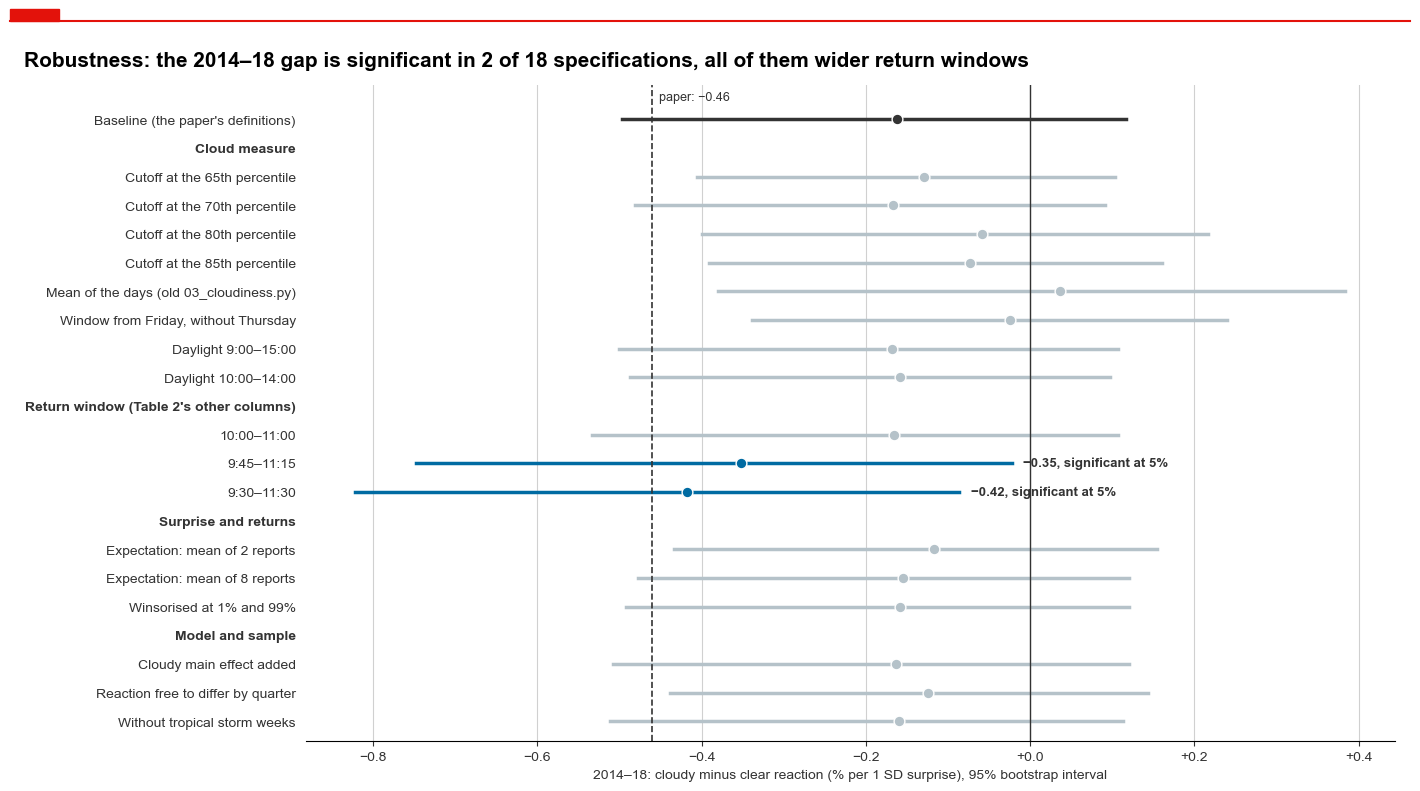

2014–18 gap with the 85th percentile −0.07, mean of the days +0.04, from Friday −0.02, 8-report expectation −0.15; 2007–11 specifications significant at 5%: 0


In [20]:
layout = []  # (label, is a group header), from the top down
for group, tests in ROBUSTNESS_GROUPS.items():
    layout += ([(group, True)] if group else []) + [(label, False) for label in tests]
positions = np.arange(len(layout))[::-1]
gaps_4 = robustness["2014–18"]
significant = [label for label in gaps_4.index if gaps_4.loc[label, "high"] < 0 or gaps_4.loc[label, "low"] > 0]

fig, ax = plt.subplots(figsize=(14, 7.6))
for (label, header), y in zip(layout, positions):
    if header or label not in gaps_4.index:
        continue
    estimate, low, high = gaps_4.loc[label, ["estimate", "low", "high"]]
    color = GAP if label in significant else DARK if label.startswith("Baseline") else "#B5C2C9"
    ax.plot([low, high], [y, y], color=color, lw=2.5)
    ax.scatter(estimate, y, color=color, s=60, zorder=3, edgecolor="white")
    if label in significant:
        annotate(ax, minus_sign(f"{estimate:+.2f}, significant at 5%"), (high, y), offset=(8, 0), color=DARK,
                 fontweight="bold")
paper_gap = PAPER_TABLES_2_3["2014–18"][2][0]
ax.axvline(paper_gap, color=PAPER, lw=1.2, ls="--")
annotate(ax, minus_sign(f"paper: {paper_gap:+.2f}"), (paper_gap, positions[0] + 0.75), offset=(5, 0), fontsize=9)
ax.axvline(0, color=DARK, lw=1)
ax.set_yticks(positions, [label for label, _ in layout])
for tick, (_, header) in zip(ax.get_yticklabels(), layout):
    tick.set_fontweight("bold" if header else "normal")
ax.set_ylim(positions[-1] - 0.7, positions[0] + 1.2)
ax.set_xlabel("2014–18: cloudy minus clear reaction (% per 1 SD surprise), 95% bootstrap interval")
ax.xaxis.set_major_formatter(SIGNED)
vertical_grid(ax)
window_rows = set(ROBUSTNESS_GROUPS["Return window (Table 2's other columns)"])
show(f"Robustness: the 2014–18 gap is significant in {len(significant)} of {len(gaps_4)} specifications"
     + (", all of them wider return windows" if significant and set(significant) <= window_rows else ""))
SHORT_NAMES = {"Cutoff at the 85th percentile": "85th percentile", "Mean of the days (old 03_cloudiness.py)":
               "mean of the days", "Window from Friday, without Thursday": "from Friday",
               "Expectation: mean of 8 reports": "8-report expectation"}
print(minus_sign("2014–18 gap with the " + ", ".join(f"{short} {robustness['2014–18'].loc[label, 'estimate']:+.2f}"
                                                    for label, short in SHORT_NAMES.items())
                 + f"; 2007–11 specifications significant at 5%: {(robustness['2007–11']['p'] < 0.05).sum()}"))
if "cloud_min_fixed" in reports:
    fixed_week, our_week = weeks_of("2014–18", cloud="cloud_min_fixed"), weeks_of("2014–18")
    fixed_day = pd.read_csv(FIXED_AIRPORTS, index_col=0, parse_dates=True)["cloudiness"]
    fixed_gap = robustness["2014–18"].loc["Fixed airports (03_cloudiness.py), 2014–18 only"]
    print(minus_sign(f"Fixed airports: daily mean {fixed_day.mean():.3f} (ours {daily_cloud[fixed_day.index].mean():.3f}, "
                     f"correlation {fixed_day.corr(daily_cloud):.2f}), {fixed_week['cloudy'].ne(our_week['cloudy']).sum()} "
                     f"of {len(our_week)} weeks labelled differently, gap {fixed_gap['estimate']:+.2f} (p = {fixed_gap['p']:.2f})"))

**Comments – Task #4**
* **The window matters most:** the 2014–18 gap is negative in 18 of 19 specifications but significant only in the paper's two widest windows (9:45–11:15: −0.35, p = 0.04; 9:30–11:30: −0.42, p = 0.02). In the main window it stays between −0.17 and −0.06 under the paper's checks (cutoffs from 65% to 85%, daylight hours, expectations, winsorising, a Cloudy main effect), within the same quarter, without the 5 storm weeks (1 of them cloudy) and with one fixed airport per hub (−0.11; 16 of 261 weeks change label).
* **The least cloudy day matters:** averaging the week's days, as `03_cloudiness.py` did before our fix, turns the gap to +0.04, and a window from Friday shrinks it to −0.02.
* **Pre-period:** the gap scatters around zero and is never significant, as the placebo requires.

## Task #5 – Out of sample: 2019 to August 2025
The paper ends in 2018 and warns that radar satellites, which see through clouds, may weaken the instrument. We rerun Table 2 on 2019 to August 2025 (when NOAA's weather data end) and on rolling five-year windows, each with its own cutoff and scaling. Since April 2020 USO also holds later contracts, so it follows the front month a little less closely.

In [21]:
oos = weeks_of("2019–25")
oos_results = {"2019–25": reaction(oos), "2019–25 without 2020": reaction(oos[oos["release"].dt.year != 2020]),
               "2020 only": reaction(oos[oos["release"].dt.year == 2020])}
pd.concat({name: paper_style(result) for name, result in oos_results.items()}, axis=1)

,2019–25,2019–25 without 2020,2020 only
β clear,−0.08* (0.08),−0.07 (0.20),−0.17 (0.11)
β cloudy,−0.02 (0.74),0.02 (0.86),−0.32 (0.30)
Difference,0.06 (0.56),0.09 (0.39),−0.15 (0.66)
R²,0.01,0.01,0.05
Observations,346,293,53


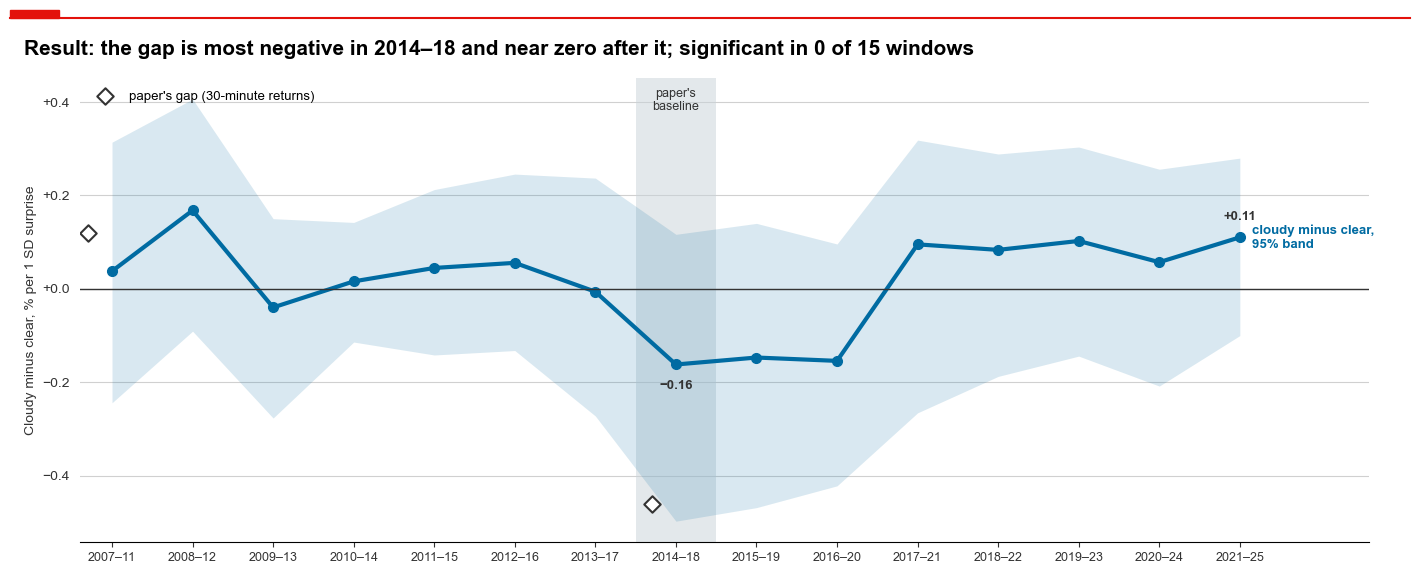

Gap by window: −0.16 at least (window ending 2018), +0.17 at most (ending 2012); significantly negative in 0 windows, significantly positive in 0


In [22]:
WINDOW_YEARS = 5  # length of the rolling samples, as the paper's periods
rolling = {}
for last_year in range(2007 + WINDOW_YEARS - 1, 2026):
    sample = weeks_of((f"{last_year - WINDOW_YEARS + 1}-01-01", min(f"{last_year}-12-31", PERIODS["2019–25"][1])))
    rolling[last_year] = reaction(sample).stack()
rolling = pd.DataFrame(rolling).T

fig, ax = plt.subplots(figsize=(14, 5.5))
years = rolling.index
ax.axvspan(2017.5, 2018.5, color=LIGHT_GREY, alpha=0.5, lw=0)
ax.text(2018, 0.98, "paper's\nbaseline", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9,
        color=DARK)
ax.fill_between(years, rolling[("gap", "low")], rolling[("gap", "high")], color=GAP, alpha=0.15, lw=0)
ax.plot(years, rolling[("gap", "estimate")], color=GAP, lw=3, marker="o", ms=7)
annotate(ax, "cloudy minus clear,\n95% band", (years[-1], rolling[("gap", "estimate")].iloc[-1]), color=GAP, fontweight="bold")
for year in (rolling[("gap", "estimate")].idxmin(), years[-1]):
    annotate(ax, minus_sign(f"{rolling.loc[year, ('gap', 'estimate')]:+.2f}"), (year, rolling.loc[year, ("gap", "estimate")]),
             offset=(0, -15 if year != years[-1] else 15), ha="center", color=DARK, fontweight="bold")
for year, period in [(2011, "2007–11"), (2018, "2014–18")]:  # beside our estimate of the same window
    ax.scatter(year - 0.3, PAPER_TABLES_2_3[period][2][0], marker="D", s=70, facecolor="white", edgecolor=PAPER,
               lw=1.5, zorder=4)
ax.scatter([], [], marker="D", s=70, facecolor="white", edgecolor=PAPER, lw=1.5, label="paper's gap (30-minute returns)")
ax.legend(loc="upper left", fontsize=9.5)
ax.axhline(0, color=DARK, lw=1)
ax.set_xticks(years, [f"{year - WINDOW_YEARS + 1}–{str(year)[2:]}" for year in years], rotation=0, fontsize=9)
ax.set_xlim(years[0] - 0.4, years[-1] + 1.6)
ax.yaxis.set_major_formatter(SIGNED)
ax.set_ylabel("Cloudy minus clear, % per 1 SD surprise")
significant_windows = ((rolling[("gap", "high")] < 0) | (rolling[("gap", "low")] > 0)).sum()
lowest = rolling[("gap", "estimate")].idxmin()
show(f"Result: the gap is most negative in {lowest - WINDOW_YEARS + 1}–{str(lowest)[2:]} and near zero after it; "
     f"significant in {significant_windows} of {len(rolling)} windows", save="a4_out_of_sample")
negative_windows = rolling.index[rolling[("gap", "high")] < 0]
positive_windows = rolling.index[rolling[("gap", "low")] > 0]
print(minus_sign(f"Gap by window: {rolling[('gap', 'estimate')].min():+.2f} at least (window ending "
                 f"{rolling[('gap', 'estimate')].idxmin()}), {rolling[('gap', 'estimate')].max():+.2f} at most (ending "
                 f"{rolling[('gap', 'estimate')].idxmax()}); significantly negative in {len(negative_windows)} windows, "
                 f"significantly positive in {len(positive_windows)}"))

**Comments – Task #5**
* **The gap is gone after 2018:** in 2019–25 a 1 SD surprise moves USO by −0.08% in clear and −0.02% in cloudy weeks, a gap of +0.06 (p = 0.56); without 2020 it is +0.09, in 2020 alone −0.15.
* **Only the paper's window stands out:** over rolling five-year windows the gap is most negative in 2014–18 (−0.16) and the two windows after it, and slightly positive from 2017–21 on (+0.06 to +0.11); none is significant in the main window.
* **Reading:** radar satellites that see through clouds, or simply more satellites, would shrink the gap to zero, as we find. But with a 2014–18 gap that is significant only in the wider windows, we cannot tell an effect that faded from one that was smaller than the paper's from the start.

## Conclusion of part (a)

In [23]:
def cell(estimate, p, digits=2):
    '''An estimate with the paper's significance stars.'''
    return minus_sign(f"{estimate:+.{digits}f}{stars(p)}")


oos = weeks_of("2019–25")
wide_oos = reaction(with_window(oos, "09:30", "11:30")).loc["gap"]
placebos = [results[name].loc["gap", "p"] for name in ("2007–11", "12:30", "no report")]
nw_p = {period: 2 * norm.sf(abs(gap / se)) for period, (gap, se) in ((p, gaps_5[p]["All days (paper)"]) for p in PERIODS)}
gap_5 = {period: gaps_5[period]["All days (paper)"][0] for period in PERIODS}
wide = window_gaps[("09:30", "11:30")]
pd.DataFrame({
    "Table 2: cloudy minus clear, 10:30–11:00": ["−0.46***", cell(*results["2014–18"].loc["gap", ["estimate", "p"]]),
                                                 cell(*oos_results["2019–25"].loc["gap", ["estimate", "p"]]), "a third of the paper's, not significant"],
    "Table 2: cloudy minus clear, 9:30–11:30": ["−0.48***", cell(wide["estimate"], wide["p"]), cell(wide_oos["estimate"], wide_oos["p"]),
                                                "replicated in 2014–18, gone after"],
    "Table 3: three placebos": ["no gap", f"{sum(p < 0.05 for p in placebos)} of 3 significant", "–", "replicated"],
    "Table 5: implied variance, cloudy minus clear days": [
        "+0.015**", cell(gap_5["2014–18"], nw_p["2014–18"], 3), cell(gap_5["2019–25"], nw_p["2019–25"], 3),
        "same size, but not significant with Newey-West errors"],
    "Table 6: first clear day minus other days": ["−0.12", cell(*results_6["2014–18"].loc["gap", ["estimate", "p"]]),
                                                  cell(*results_6["2019–25"].loc["gap", ["estimate", "p"]]), "no effect, as in the paper"],
}, index=["Paper, 2014–18", "Ours, 2014–18", "Ours, 2019–25", "Verdict"]).T

,"Paper, 2014–18","Ours, 2014–18","Ours, 2019–25",Verdict
"Table 2: cloudy minus clear, 10:30–11:00",−0.46***,−0.16,+0.06,"a third of the paper's, not significant"
"Table 2: cloudy minus clear, 9:30–11:30",−0.48***,−0.42**,+0.18,"replicated in 2014–18, gone after"
Table 3: three placebos,no gap,0 of 3 significant,–,replicated
"Table 5: implied variance, cloudy minus clear days",+0.015**,+0.016,+0.027,"same size, but not significant with Newey-West..."
Table 6: first clear day minus other days,−0.12,+0.00,+0.28,"no effect, as in the paper"


* **Main result (Table 2, Figure 5):** with USO's one-minute prices our returns are as precise as the paper's. In 2014–18 cloudy weeks react more strongly than clear weeks, as in the paper, but more slowly: the gap is −0.16 (p = 0.25) in the paper's 10:30–11:00 window and −0.42 (p = 0.02) from 9:30 to 11:30 (paper −0.46 and −0.48).
* **Placebos (Table 3):** no gap in 2007–11, from 12:30 to 1:00 p.m. or on days without a report, as in the paper; in 2007–11 our Figure 5 lies on the paper's.
* **Mechanism (Tables 5 and 6):** Table 5 replicates to the third decimal, but its significance comes from comparing different months; we find no move on the day after the first clear day.
* **Out of sample:** after 2018 the gap is gone (+0.06, p = 0.56).
* **Next steps:** Table 7 (price jumps) with the minute data, and minute bars of the WTI futures themselves (LSEG `CLc1`) to check that the delay in 2014–18 is not USO's.

# (b) Can a normal person copy the satellite funds?

Satellite funds buy images at 30 to 50 cm. We try the free version: **Sentinel 2** (10 m pixels, every five
days) over **Cushing, Oklahoma**, the delivery point of WTI, and EIA's weekly **Cushing stocks** to check against.

1. **Tank map:** 415 storage tanks from OpenStreetMap, turned into circles on the Sentinel 2 pixels. We keep the
   398 built by 2018 whose roof is not permanently dark.
2. **Shadow index:** on each image, dark pixels on the roofs divided by dark pixels in the shadow the tanks cast
   on the ground. A floating roof sinks as the tank empties, so more of it lies in the wall's shadow: a higher
   ratio means emptier tanks. Sun direction and shadow length come from each image; tanks are 15 m high.
3. **Images:** 2017 to 2024, tile cloud cover below 5%, sun lower than 45° (winter, when shadows are long).

From `Satellite_Group4.ipynb`, reading every image from the cache in `data/cache/`. The experiments behind the
improved index are in `early_stage_notebooks/Satellite_experiments.ipynb` (appendix).

In [24]:
CUSHING = (35.985, -96.767)  # town centre, from config.py, used for the search
CENTRE = (35.967, -96.750)   # 2 km south, 1.5 km east: centre of the window
HALF_KM = 7                  # 14 km square, covers all three farms

import json
from pathlib import Path

CACHE = Path("data/cache")


def search_items():
    """All Sentinel 2 images over Cushing, 2017 to 2024 (searched once, then read from the cache)."""
    path = CACHE / "s2_items_2017_2024.json"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        found = []
        for year in range(2017, 2025):  # one search per year: a search returns at most 200 images
            found += viz.s2_search(*CUSHING, f"{year}-01-01", f"{year}-12-31")
        path.write_text(json.dumps(found))
    found = json.loads(path.read_text())
    # ten images sit in a paid ("requester pays") bucket with s3:// links: we skip them
    return [item for item in found if item["assets"]["visual"]["href"].startswith("https")]


def load_chip(item):
    """RGB window around CENTRE, downloaded once and then read from the cache."""
    path = CACHE / "s2" / f"{item['id']}.npy"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        chip = viz.s2_chip(item, *CENTRE, half_km=HALF_KM)
        np.save(path, chip)
        props = item["properties"]
        meta = {"id": item["id"], "datetime": props["datetime"], "tile": props["mgrs:grid_square"],
                "processing_baseline": props["s2:processing_baseline"],
                "cloud_cover": props["eo:cloud_cover"], "sun_azimuth": props["view:sun_azimuth"],
                "sun_elevation": props["view:sun_elevation"],
                "no_data": float((chip.sum(axis=2) == 0).mean()),
                "href": item["assets"]["visual"]["href"], "centre": CENTRE, "half_km": HALF_KM}
        path.with_suffix(".json").write_text(json.dumps(meta, indent=1))
    return np.load(path)

In [25]:
items = [item for item in search_items() if item["properties"]["datetime"][:4] == "2018"]
clear = [item for item in items if item["properties"]["eo:cloud_cover"] < 5]
print(f"{len(items)} images in 2018, {len(clear)} almost cloud free")

for item in clear:
    chip = load_chip(item)
    no_data = (chip.sum(axis=2) == 0).mean()  # share of black pixels
    if no_data < 0.01:
        break

reference = item  # the image we draw the tank map on
date = item["properties"]["datetime"][:10]
print(date, f"{no_data:.1%} black pixels")

147 images in 2018, 52 almost cloud free


2018-01-20 0.6% black pixels


## b.1 The tank map

In [26]:
#-----Overpass API------#

import requests

BOX = (35.904, -96.828, 36.030, -96.672)  # south, west, north, east of our 14 km window
query = f"""
[out:json];
nwr["man_made"="storage_tank"]{BOX};
out geom;
"""

HEADERS = {
    "User-Agent": "Bocconi student project (Finance with Big Data), contact: giuliano",
    "Accept": "application/json",
}
URL = "https://overpass-api.de/api/interpreter"

path = CACHE / "osm_tanks.json"
if not path.exists():  # ask OpenStreetMap only once
    answer = requests.post(URL, data={"data": query}, headers=HEADERS, timeout=120)
    answer.raise_for_status()
    path.write_text(answer.text)

tanks = json.loads(path.read_text())["elements"]
print(f"{len(tanks)} objects in OpenStreetMap")
for kind in ("node", "way", "relation"):
    print(kind, sum(t["type"] == kind for t in tanks))

415 objects in OpenStreetMap
node 0
way 415
relation 0


In [27]:
from affine import Affine
from rasterio.transform import rowcol
from rasterio.warp import transform

# Pixel grid of the tile, from the image metadata (no download needed)
grid = Affine(*item["assets"]["visual"]["proj:transform"][:6])
crs = f"EPSG:{item['properties']['proj:epsg']}"
(cx,), (cy,) = transform("EPSG:4326", crs, [CENTRE[1]], [CENTRE[0]])
row0, col0 = rowcol(grid, cx, cy)
half = int(HALF_KM * 1000 / 10)       # 10 m pixels
top, left = row0 - half, col0 - half  # first row and column of our chip
to_image = ~grid                      # satellite map coordinates to (column, row)

centres, radii = [], []
for tank in tanks:
    points = tank["geometry"][:-1]        # the last point repeats the first
    lons = [p["lon"] for p in points]
    lats = [p["lat"] for p in points]
    xs, ys = transform("EPSG:4326", crs, lons, lats)
    cols, rows = zip(*[to_image * (x, y) for x, y in zip(xs, ys)])
    cols, rows = np.array(cols) - left, np.array(rows) - top
    centres.append((rows.mean(), cols.mean()))
    radii.append(np.hypot(rows - rows.mean(), cols - cols.mean()).mean())

centres, radii = np.array(centres), np.array(radii)
print(f"Radius: median {np.median(radii) * 10:.0f} m, "
      f"smallest {radii.min() * 10:.0f} m, largest {radii.max() * 10:.0f} m")

Radius: median 31 m, smallest 9 m, largest 43 m


In [28]:
def tank_brightness(gray, centres, radii):
    """Mean brightness inside each tank circle (0 = black, 1 = white)."""
    values = []
    for (row, col), r in zip(centres, radii):
        r = max(r, 1)  # very small tanks: use at least one pixel
        top, left = int(row - r), int(col - r)
        window = gray[top:int(row + r) + 1, left:int(col + r) + 1]
        rr, cc = np.indices(window.shape)
        inside = np.hypot(rr + top + 0.5 - row, cc + left + 0.5 - col) <= r
        values.append(window[inside].mean())
    return np.array(values)

brightness = []
for item_k in clear[::6]:  # every 6th clear image: about 9 dates
    chip_k = load_chip(item_k)
    brightness.append(tank_brightness(chip_k.mean(axis=2) / 255, centres, radii))
brightness = np.array(brightness)  # one row per date, one column per tank

built = brightness.max(axis=0) > 0.6  # bright on at least one date
print(f"{built.sum()} of {len(built)} tanks existed in 2018")

if len(centres) == len(built):  # only filter if not done yet
    centres, radii = centres[built], radii[built]
print(len(centres), "tanks kept")

401 of 415 tanks existed in 2018


401 tanks kept


## b.2 The shadows
`DARK_PIXEL` is the baseline's threshold: a pixel darker than 0.4 (on a 0 to 1 scale) counts as shadow. We rename
it from `DARK`, which is a colour of the chart theme.

In [29]:
gray = chip.mean(axis=2) / 255  # the reference image, 0 = black, 1 = white
sun_azimuth = item["properties"]["view:sun_azimuth"]
sun_elevation = item["properties"]["view:sun_elevation"]
TANK_HEIGHT = 15  # metres: typical Cushing tanks are 48 ft (14.6 m) high (Oil & Gas Journal; Industrial Info)

L_m = TANK_HEIGHT / np.tan(np.radians(sun_elevation))
shadow_dir = np.radians(sun_azimuth + 180)                # shadows point away from the sun
d_row, d_col = -np.cos(shadow_dir), np.sin(shadow_dir)    # rows grow southward in the image
print(f"L = {L_m:.0f} m = {L_m / 10:.1f} pixels, towards {np.degrees(shadow_dir) % 360:.0f} degrees")

L = 25 m = 2.5 pixels, towards 339 degrees


In [30]:
DARK_PIXEL = 0.4  # a pixel darker than this counts as shadow (the baseline's value)

def shadow_counts(gray, centres, radii, L_px, d_row, d_col):
    """Dark pixels on the roofs and in the ground shadows, summed over all tanks."""
    roof_dark, ground_dark = 0, 0
    per_tank = []  # dark roof pixels of each tank
    for (row, col), r in zip(centres, radii):
        reach = int(r + L_px) + 2
        top, left = int(row) - reach, int(col) - reach
        window = gray[top:int(row) + reach, left:int(col) + reach]
        rr, cc = np.indices(window.shape)
        y = rr + top + 0.5 - row  # pixel centre, relative to the tank centre
        x = cc + left + 0.5 - col

        on_roof = np.hypot(y, x) <= r
        t = np.clip(y * d_row + x * d_col, 0, L_px)  # how far along the shadow direction
        swept = np.hypot(y - t * d_row, x - t * d_col) <= r
        in_ground_shadow = swept & ~on_roof

        dark = window < DARK_PIXEL
        roof_dark += (dark & on_roof).sum()
        ground_dark += (dark & in_ground_shadow).sum()
        per_tank.append((dark & on_roof).sum())
    return roof_dark, ground_dark, per_tank

In [31]:
roof_pixels = np.array([max(np.pi * r ** 2, 1) for r in radii])  # roof area in pixels
roof_dark, ground_dark, per_tank = shadow_counts(gray, centres, radii, L_m / 10, d_row, d_col)
dark_share = np.array(per_tank) / roof_pixels

keep = dark_share < 0.7  # more than 70% dark cannot be shadow
print(f"Dropped {(~keep).sum()} dark roofed tanks, keeping {keep.sum()}")

if len(centres) == len(keep):  # only filter once
    centres, radii = centres[keep], radii[keep]
print(len(centres), "tanks")

Dropped 3 dark roofed tanks, keeping 398
398 tanks


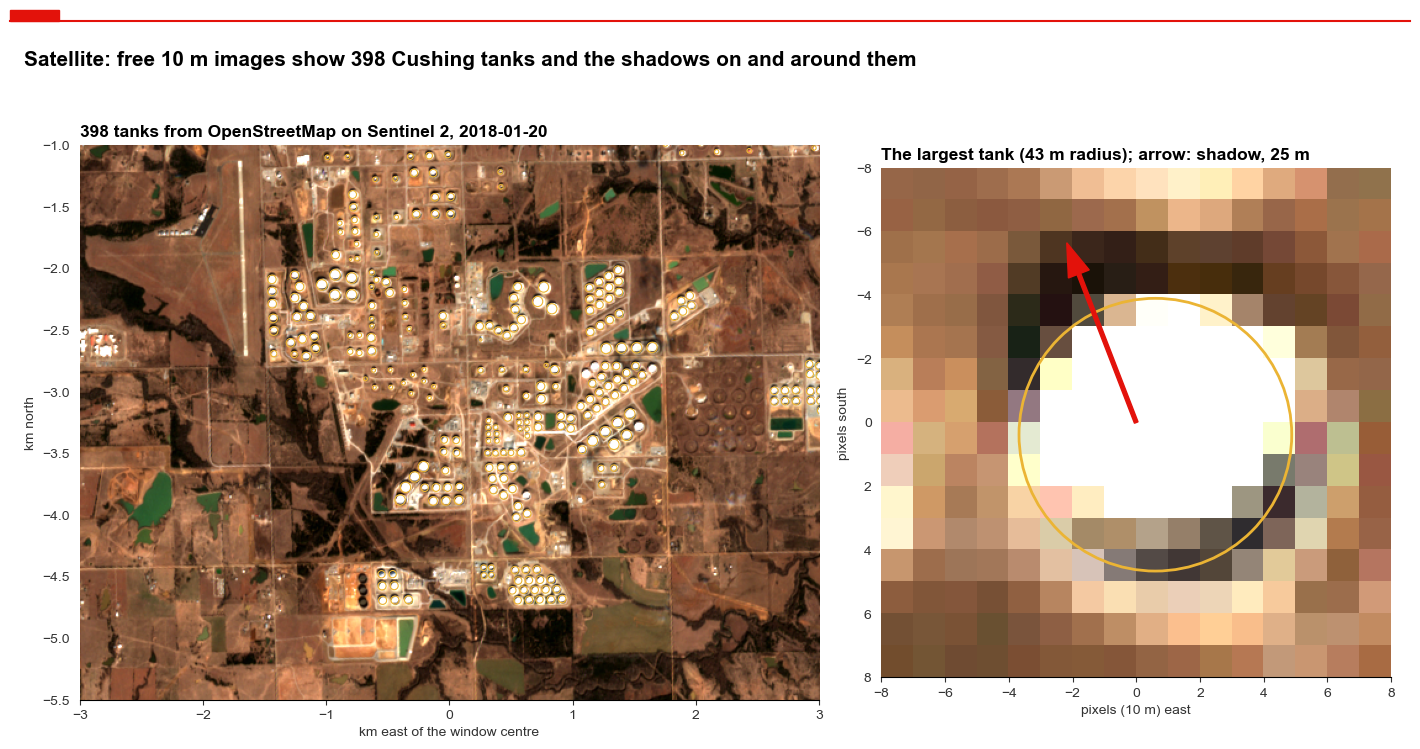

In [32]:
x_km = centres[:, 1] * 0.01 - HALF_KM  # column to km east of the window centre (10 m pixels)
y_km = HALF_KM - centres[:, 0] * 0.01  # row to km north
k = np.argmax(radii)                   # the largest tank
row, col = centres[k]
size = 8                               # pixels shown on each side of its centre
zoom = chip[int(row) - size:int(row) + size, int(col) - size:int(col) + size]

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 7.4), gridspec_kw={"width_ratios": [1.45, 1]})
left.imshow(chip, extent=[-HALF_KM, HALF_KM, -HALF_KM, HALF_KM])
for x, y, r in zip(x_km, y_km, radii * 0.01):
    left.add_patch(plt.Circle((x, y), r, color=YELLOW, fill=False, linewidth=0.8))
left.set_xlim(-3, 3)
left.set_ylim(-5.5, -1)
left.set_title(f"{len(centres)} tanks from OpenStreetMap on Sentinel 2, {date}", fontsize=12.5)
left.set_xlabel("km east of the window centre")
left.set_ylabel("km north")

right.imshow(zoom, interpolation="nearest", extent=[-size, size, size, -size])
right.add_patch(plt.Circle((col - int(col), row - int(row)), radii[k], color=YELLOW, fill=False, lw=2))
right.arrow(0, 0, 5 * d_col, 5 * d_row, color=ECONOMIST_RED, width=0.12, head_width=0.7)
right.set_title(f"The largest tank ({radii[k] * 10:.0f} m radius); arrow: shadow, {L_m:.0f} m", fontsize=12.5)
right.set_xlabel("pixels (10 m) east")
right.set_ylabel("pixels south")
for ax in (left, right):
    ax.grid(False)
show(f"Satellite: free 10 m images show {len(centres)} Cushing tanks and the shadows on and around them",
     save="b1_tank_map")

## b.3 The baseline index, rules fixed in advance
One image per day (the first one whose window has at most 1% black pixels), the shadow ratio of all 398 tanks,
and the closest weekly EIA Cushing stock. Ratios of 0.7 and more mean clouds and are dropped.

In [33]:
import pandas as pd

items = search_items()  # 2017 to 2024, from the cache

winter = [item for item in items
          if item["properties"]["eo:cloud_cover"] < 5
          and item["properties"]["view:sun_elevation"] < 45]
print(f"{len(items)} images, {len(winter)} clear with low sun")

1233 images, 169 clear with low sun


In [34]:
rows = []
for item_k in winter:
    date = item_k["properties"]["datetime"][:10]
    if date in [row["date"] for row in rows]:
        continue  # same day from a second tile: keep the first
    chip_k = load_chip(item_k)
    if (chip_k.sum(axis=2) == 0).mean() > 0.01:
        continue  # tile edge cuts our window

    elevation = item_k["properties"]["view:sun_elevation"]
    azimuth = item_k["properties"]["view:sun_azimuth"]
    L_px = TANK_HEIGHT / np.tan(np.radians(elevation)) / 10
    direction = np.radians(azimuth + 180)
    roof, ground, _ = shadow_counts(chip_k.mean(axis=2) / 255, centres, radii,
                                    L_px, -np.cos(direction), np.sin(direction))

    rows.append({"date": date, "sun_elevation": elevation,
                 "roof_dark": roof, "ground_dark": ground, "ratio": roof / ground})

index = pd.DataFrame(rows).set_index("date")
print(f"{len(index)} dates measured")

64 dates measured


In [35]:
import requests

EIA_CUSHING = "https://www.eia.gov/dnav/pet/hist_xls/W_EPC0_SAX_YCUOK_MBBLw.xls"  # weekly Cushing stocks
path = os.path.join("data", "raw", "eia_cushing_w.xls")
if not os.path.exists(path):
    reply = requests.get(EIA_CUSHING, headers={"User-Agent": "Bocconi student project"}, timeout=120)
    with open(path, "wb") as file:
        file.write(reply.content)

table = pd.read_excel(path, sheet_name="Data 1", skiprows=2)
cushing = table.set_index(table.columns[0]).iloc[:, 0].astype(float) / 1000  # million barrels

index.index = pd.to_datetime(index.index)
index["cushing_stocks"] = cushing.reindex(index.index, method="nearest").values  # closest weekly report

clean = index[index["ratio"] < 0.7]  # ratio near 1 would mean all tanks empty: clouds
print(f"Correlation without cloud images: {clean['ratio'].corr(clean['cushing_stocks']):.2f}")

Correlation without cloud images: -0.40


In [36]:
clean = index[index["ratio"] < 0.7]  # a ratio near 1 would mean all tanks empty: clouds
model = smf.ols("ratio ~ cushing_stocks + sun_elevation", data=clean).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3})  # robust to nearby dates being related
print(model.summary().tables[1])

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.5249      0.099      5.289      0.000       0.330       0.719
cushing_stocks    -0.0035      0.001     -4.642      0.000      -0.005      -0.002
sun_elevation     -0.0051      0.003     -1.591      0.112      -0.011       0.001


## b.4 Improved index (chosen after seeing results)

In `Satellite_experiments.ipynb` we tested one change at a time. We adopt the three changes that help for a
reason we can explain without the correlation:

* **Black pixels only near the tanks (experiment 1b).** We skip an image only if a black pixel lies within
  40 m of a roof. On five dates the tile edge cuts the window but misses every tank, so these dates come back.
* **Newest processing version (experiment 8).** Many days have two versions of the same tile. The baseline
  takes the older one, because it comes first in the list. We keep the newest, so all years come from
  similar processing.
* **Each image lined up with the reference (experiment 9).** Sentinel 2 places images a few metres off, and
  differently on each date. Half a pixel moves the ratio a lot. We measure each image's shift against the
  2018-01-20 image and move the circles with it. No EIA data enter this step.

**Clouds.** We flag a cloud (ratio ≥ 0.7) with the **unshifted** circles, exactly as in the baseline. Lining
up a cloudy image can move its circles far and hide the cloud.

We chose these changes after seeing the results, so the improved index is not an out-of-sample test. The
baseline above uses rules we fixed in advance, and we show both.

In [37]:
gray_ref = load_chip(reference).mean(axis=2) / 255

# Pixels within 4 pixels (40 m) of a roof: longer than the longest winter shadow (28 m)
rr, cc = np.indices(gray_ref.shape)
near_tanks = np.zeros(gray_ref.shape, dtype=bool)
for (row, col), r in zip(centres, radii):
    near_tanks |= np.hypot(rr + 0.5 - row, cc + 0.5 - col) <= r + 4

# The box around all tanks, plus 20 pixels: the part of each image we line up
top_row, left_col = (centres.min(axis=0) - 20).astype(int)
bottom_row, right_col = (centres.max(axis=0) + 20).astype(int)
FARMS = (slice(top_row, bottom_row), slice(left_col, right_col))


def newest_versions(images):
    """For each day and tile, keep only the image with the newest processing version."""
    newest = {}
    for image in images:
        key = (image["properties"]["datetime"][:10], image["properties"]["mgrs:grid_square"])
        version = float(image["properties"]["s2:processing_baseline"])
        if key not in newest or version > float(newest[key]["properties"]["s2:processing_baseline"]):
            newest[key] = image
    keep = {image["id"] for image in newest.values()}
    return [image for image in images if image["id"] in keep]


def image_shift(gray_k):
    """Shift (rows, columns) of an image against the reference image, to 0.1 pixel."""
    shift, _, _ = phase_cross_correlation(gray_ref[FARMS], gray_k[FARMS], upsample_factor=10)
    return -shift  # the function returns the shift that undoes the movement, so we flip it


def shadow_ratio(gray_k, image, shift=(0, 0), height=TANK_HEIGHT):
    """Dark roof pixels over dark ground shadow pixels, with the circles moved by `shift` pixels."""
    elevation = image["properties"]["view:sun_elevation"]
    azimuth = image["properties"]["view:sun_azimuth"]
    L_px = height / np.tan(np.radians(elevation)) / 10
    direction = np.radians(azimuth + 180)
    roof, ground, _ = shadow_counts(gray_k, centres + np.asarray(shift), radii,
                                    L_px, -np.cos(direction), np.sin(direction))
    return roof / ground

In [38]:
def improved_index(height=TANK_HEIGHT):
    """Shadow index with changes 1b, 8 and 9. The cloud flag uses the unshifted circles."""
    rows = []
    for image in newest_versions(winter):
        date = image["properties"]["datetime"][:10]
        if date in [row["date"] for row in rows]:
            continue  # this day is already measured
        chip_k = load_chip(image)
        if (chip_k.sum(axis=2) == 0)[near_tanks].any():
            continue  # the tile edge cuts a tank or its shadow
        gray_k = chip_k.mean(axis=2) / 255
        shift = image_shift(gray_k)
        if np.abs(shift).max() > 2:
            shift = np.zeros(2)  # failed match: keep the circles where they are
        rows.append({"date": date, "sun_elevation": image["properties"]["view:sun_elevation"],
                     "unshifted_ratio": shadow_ratio(gray_k, image, height=height),  # flags image clouds
                     "ratio": shadow_ratio(gray_k, image, shift, height),
                     "shift_m": 10 * np.hypot(*shift)})
    improved = pd.DataFrame(rows).set_index("date")
    improved.index = pd.to_datetime(improved.index)
    improved["cushing_stocks"] = cushing.reindex(improved.index, method="nearest").values
    return improved


improved = improved_index()
print(f"{len(improved)} dates. We move the circles by {improved['shift_m'].median():.1f} m on the median "
      f"date, {improved['shift_m'].max():.0f} m at most.")

69 dates. We move the circles by 3.2 m on the median date, 14 m at most.


**Tank height.** We keep 15 m: typical Cushing tanks are 48 ft (14.6 m) high (Oil & Gas Journal; Industrial
Info). We show 18 m as a realistic robustness check, and 12 m as a stress test below the reported Cushing tank
height.

In [39]:
def test(data, cloud_column="ratio"):
    """Dates, correlation without clouds, and the HAC regression of the ratio on stocks."""
    clean = data[data[cloud_column] < 0.7]  # a ratio near 1 would mean all tanks empty: clouds
    model = smf.ols("ratio ~ cushing_stocks + sun_elevation", data=clean).fit(
        cov_type="HAC", cov_kwds={"maxlags": 3})
    return {"dates": len(data), "dates without clouds": len(clean),
            "correlation": clean["ratio"].corr(clean["cushing_stocks"]),
            "stocks coef": model.params["cushing_stocks"], "HAC z": model.tvalues["cushing_stocks"]}


comparison = pd.DataFrame({
    "Baseline, 15 m (rules fixed in advance)": test(index),
    "Improved, 15 m (chosen after seeing results)": test(improved, "unshifted_ratio"),
    "Improved, 18 m (robustness)": test(improved_index(18), "unshifted_ratio"),
    "Improved, 12 m (stress test, below the reported Cushing tank height)": test(improved_index(12),
                                                                                 "unshifted_ratio"),
}).T
comparison = comparison.astype({"dates": int, "dates without clouds": int})
# explicit format: the theme shows 3 decimals, too few for the coefficient
comparison.style.format({"correlation": "{:.2f}", "stocks coef": "{:.4f}", "HAC z": "{:.1f}"})

,dates,dates without clouds,correlation,stocks coef,HAC z
"Baseline, 15 m (rules fixed in advance)",64,62,-0.40,-0.0035,-4.6
"Improved, 15 m (chosen after seeing results)",69,67,-0.66,-0.0037,-6.1
"Improved, 18 m (robustness)",69,68,-0.64,-0.0033,-6.0
"Improved, 12 m (stress test, below the reported Cushing tank height)",69,65,-0.67,-0.0043,-6.0


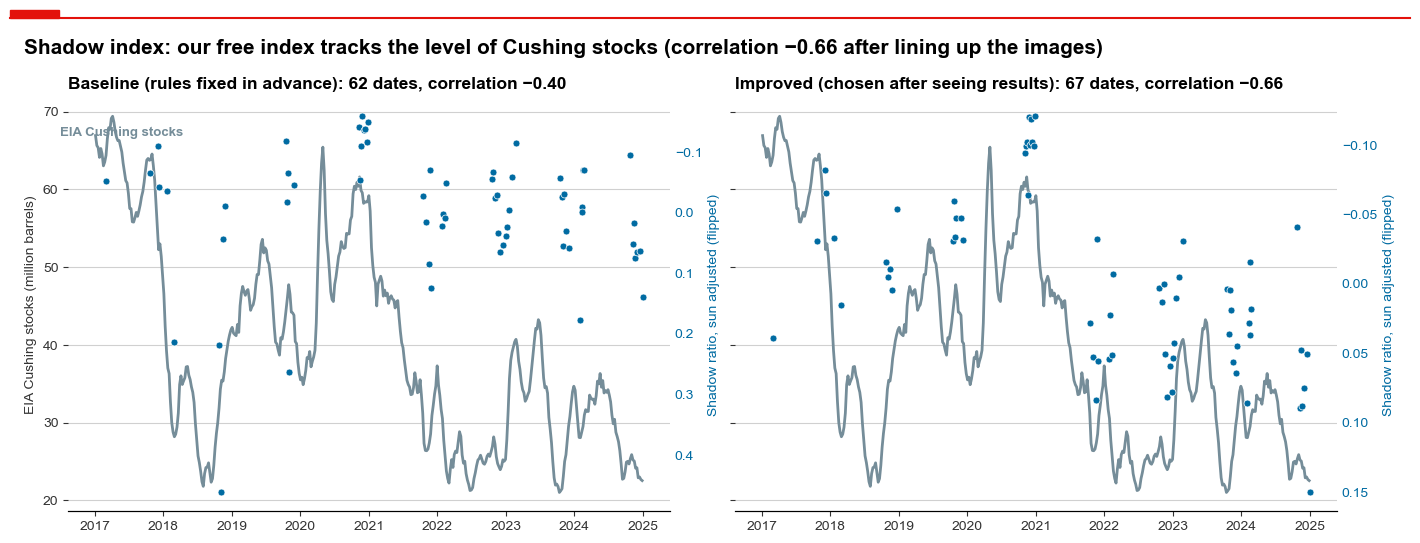

In [40]:
versions = {"Baseline (rules fixed in advance)": index[index["ratio"] < 0.7],
            "Improved (chosen after seeing results)": improved[improved["unshifted_ratio"] < 0.7]}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, (name, data) in zip(axes, versions.items()):
    sun_fit = np.polyfit(data["sun_elevation"], data["ratio"], 1)
    adjusted = data["ratio"] - np.polyval(sun_fit, data["sun_elevation"])  # what the sun does not explain
    ax.plot(cushing["2017":"2024"], color=GREY, lw=2)
    ax.set_ylabel("EIA Cushing stocks (million barrels)" if ax is axes[0] else "")
    flipped = ax.twinx()
    flipped.plot(data.index, adjusted, "o", color=BLUE, markersize=5, markeredgecolor="white", markeredgewidth=0.5)
    flipped.invert_yaxis()  # flipped: more shadow should line up with fewer barrels
    flipped.grid(False)
    flipped.spines["right"].set_visible(False)
    flipped.set_ylabel("Shadow ratio, sun adjusted (flipped)", color=BLUE)
    flipped.tick_params(axis="y", colors=BLUE, length=0)
    ax.set_title(minus_sign(f"{name}: {len(data)} dates, correlation {data['ratio'].corr(data['cushing_stocks']):.2f}"),
                 fontsize=12.5)
annotate(axes[0], "EIA Cushing stocks", (cushing["2017"].index[20], cushing["2017"].iloc[20]), offset=(0, 14),
         color=GREY, fontweight="bold")
best = versions["Improved (chosen after seeing results)"]
show(f"Shadow index: our free index tracks the level of Cushing stocks (correlation "
     + minus_sign(f"{best['ratio'].corr(best['cushing_stocks']):.2f}") + " after lining up the images)",
     save="b2_index_vs_cushing")

## b.5 Levels, not weekly changes
The EIA number is news about the **change** in stocks. So the question for a trader is not whether the index
follows the level, but whether it sees the change between two dates. Rule from `Satellite_experiments.ipynb`
(experiments 7a and 10, fixed before looking): consecutive cloud free dates at most 30 days apart, change in the
ratio on the change in stocks and in sun elevation, HAC errors with 3 lags.

Levels: 67 dates, correlation -0.66, HAC z -6.1
Changes: 53 pairs, correlation -0.20, HAC z -1.8; median change in stocks 1.2 million barrels


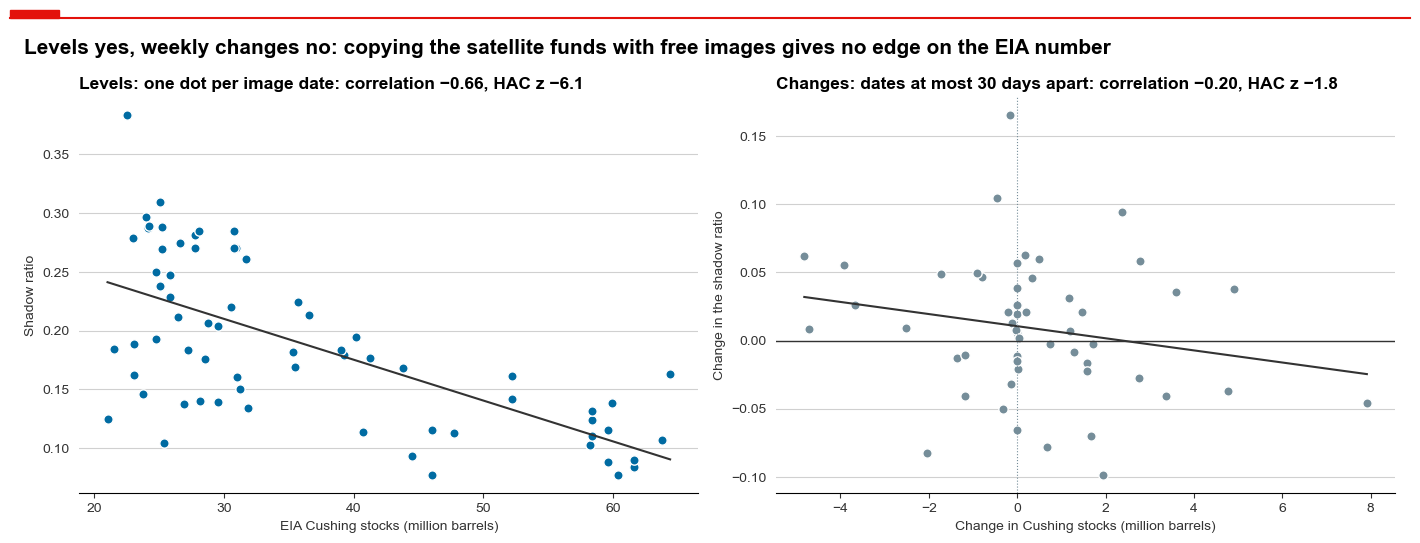

In [41]:
clean = improved[improved["unshifted_ratio"] < 0.7]
changes = clean[["ratio", "cushing_stocks", "sun_elevation"]].diff()
pairs = changes[clean.index.to_series().diff().dt.days <= 30]
levels_fit = smf.ols("ratio ~ cushing_stocks + sun_elevation", data=clean).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3})
changes_fit = smf.ols("ratio ~ cushing_stocks + sun_elevation", data=pairs).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3})
level_corr = clean["ratio"].corr(clean["cushing_stocks"])
change_corr = pairs["ratio"].corr(pairs["cushing_stocks"])
print(f"Levels: {len(clean)} dates, correlation {level_corr:.2f}, HAC z {levels_fit.tvalues['cushing_stocks']:.1f}")
print(f"Changes: {len(pairs)} pairs, correlation {change_corr:.2f}, HAC z {changes_fit.tvalues['cushing_stocks']:.1f}; "
      f"median change in stocks {pairs['cushing_stocks'].abs().median():.1f} million barrels")

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.2))
left.scatter(clean["cushing_stocks"], clean["ratio"], s=45, color=BLUE, edgecolor="white")
right.scatter(pairs["cushing_stocks"], pairs["ratio"], s=45, color=GREY, edgecolor="white")
for ax, data, corr, fit, title in [
        (left, clean, level_corr, levels_fit, "Levels: one dot per image date"),
        (right, pairs, change_corr, changes_fit, "Changes: dates at most 30 days apart")]:
    slope, intercept = np.polyfit(data["cushing_stocks"], data["ratio"], 1)
    line = np.array([data["cushing_stocks"].min(), data["cushing_stocks"].max()])
    ax.plot(line, intercept + slope * line, color=DARK, lw=1.5)
    ax.set_title(minus_sign(f"{title}: correlation {corr:.2f}, HAC z {fit.tvalues['cushing_stocks']:.1f}"),
                 fontsize=12.5)
left.set_xlabel("EIA Cushing stocks (million barrels)")
left.set_ylabel("Shadow ratio")
right.set_xlabel("Change in Cushing stocks (million barrels)")
right.set_ylabel("Change in the shadow ratio")
right.axhline(0, color=DARK, lw=1)
right.axvline(0, color=GREY, lw=0.8, ls=":")
show("Levels yes, weekly changes no: copying the satellite funds with free images gives no edge on the EIA number",
     save="b3_levels_vs_changes")

## b.6 What the experiments showed (appendix: `early_stage_notebooks/Satellite_experiments.ipynb`)
One change at a time against the baseline, rules fixed before running each one; numbers from the appendix
notebook, not recomputed here. "Dates" are the cloud free dates (pairs of dates for the "changes" rows).

| Experiment | Dates | Correlation | Stocks coefficient | HAC z |
|---|---|---|---|---|
| Baseline (rules fixed in advance) | 62 | −0.40 | −0.0035 | −4.6 |
| 1b. Black pixels checked only near the tanks | 66 | −0.35 | −0.0034 | −4.6 |
| 2. Cloud check over our window only | 73 | −0.41 | −0.0035 | −3.6 |
| 3b. Dark threshold relative to each image | 61 | −0.28 | −0.0022 | −3.0 |
| 4. Tanks 12 m high (sensitivity) | 61 | −0.52 | −0.0044 | −5.2 |
| 4. Tanks 18 m high (sensitivity) | 62 | −0.39 | −0.0031 | −4.3 |
| 5. Summer images only (sun ≥ 45°) | 71 | 0.13 | 0.0015 | 1.1 |
| 6. Circles moved 5 m south | 63 | −0.72 | −0.0058 | −9.4 |
| 6. Circles moved 5 m north | 58 | −0.10 | −0.0012 | −0.7 |
| 7a. Changes, baseline | 48 | 0.19 | 0.0121 | 1.4 |
| 7b. Within each winter, baseline | 62 | −0.27 | −0.0053 | −2.5 |
| 8. Newest processing version | 62 | −0.49 | −0.0041 | −5.9 |
| 9. Images lined up with the reference | 62 | −0.62 | −0.0035 | −5.5 |
| 10. Combined 1b + 8 + 9 (the improved index) | 67 | −0.66 | −0.0037 | −6.1 |
| 10. Combined, changes | 53 | −0.20 | −0.0027 | −1.8 |
| 10. Combined, within each winter | 67 | −0.18 | −0.0021 | −2.6 |

* **Where the circles sit matters most:** half a pixel (5 m) moves the ratio by 12% to 51% and the correlation
  from −0.10 to −0.72. Lining up each image with the reference (experiment 9) removes most of this noise, using
  only the pictures.
* **Summer images carry no signal:** with the sun above 45° the shadows are shorter than one pixel.
* **Levels, not changes:** the improved index follows the level of Cushing stocks, but the link between changes is
  weak (correlation −0.20, z −1.8) and no better than the baseline within a winter (z −2.6 against −2.5).

**Comments**
* **Stronger link to the stocks.** The improved index keeps 67 dates without clouds (baseline 62). Its correlation with EIA Cushing stocks rises from −0.40 to −0.66, and the HAC z from −4.6 to −6.1. The slope barely changes (−0.0037 against −0.0035), so the gain comes from less noise, not from a different relation.
* **Tank height no longer matters much.** With 18 m the correlation is −0.64, with 12 m −0.67. In the baseline the two heights gave −0.39 and −0.52 (Section b.6).
* **Small shifts, big effect.** We move the circles by 3.2 m on the median date and by 14 m at most, less than one and a half pixels.
* **Levels, not weekly changes.** The index follows the level of Cushing stocks. Between dates at most 30 days apart the link is weak (z −1.8, Section b.5), so it gives us no edge on the weekly EIA number.

# (c) What to do instead: the cloud straddle

A normal investor cannot see the tanks, but can see the clouds: NOAA's airport reports are free. If cloudy weeks
bring bigger moves on the EIA report, a straddle (a call and a put on USO) bought before the report in cloudy
weeks only should pay more than one bought every week. From `Strategy_Group4.ipynb`; the release dates, surprises,
cloudy weeks and USO minute prices are those of part (a).

**Two different questions.** The paper's mechanism is a **steeper reaction**: in cloudy weeks the price reacts more
strongly per unit of inventory surprise (a signed slope). Our straddle needs a **bigger move**: it pays when the
absolute price change is large, whatever its sign. A straddle cannot trade the paper's mechanism on its own, so we
test whether cloudy weeks also bring bigger moves. The two are not the same thing, and we keep them apart.

## c.1 Two questions in one picture (2014–18)

clear: slope -0.12% per SD (10:30-11:00), mean absolute daily move 1.701%
cloudy: slope -0.28% per SD (10:30-11:00), mean absolute daily move 2.014%


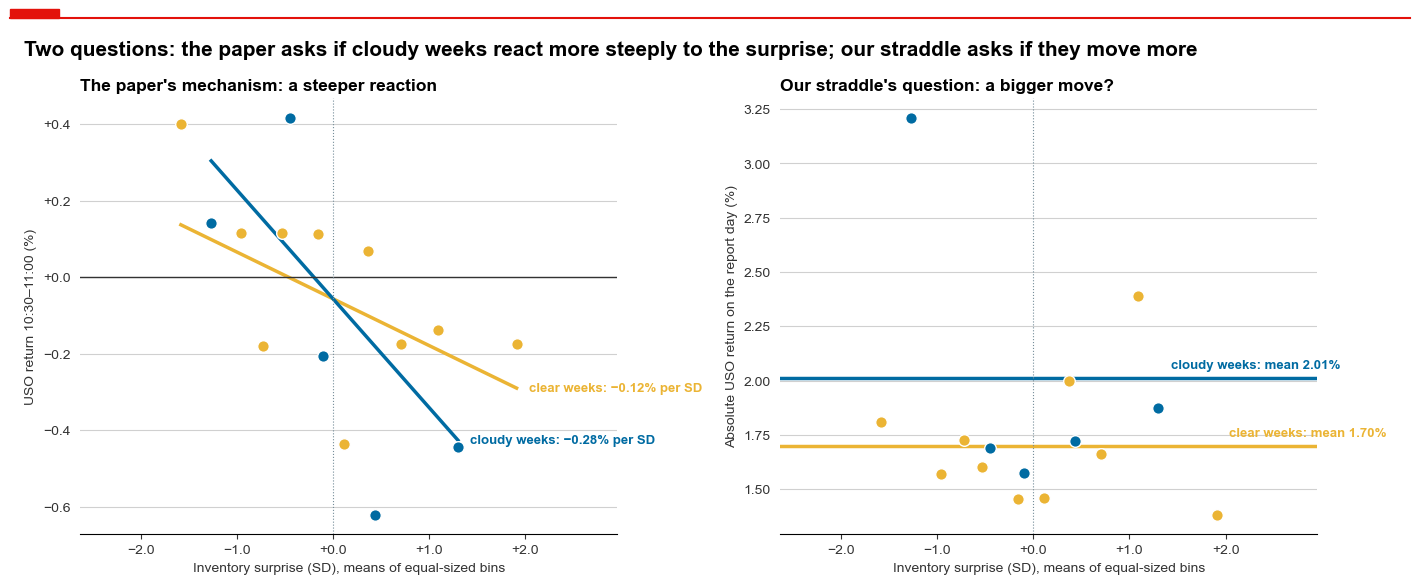

In [42]:
uso_returns = pd.read_csv(os.path.join(RAW, "optionmetrics_uso_prices.csv"), parse_dates=["date"],
                          index_col="date")["return"]
weeks = base.assign(daily_move=100 * base["release"].map(uso_returns).abs())  # part (a)'s 2014-18 weeks
estimate = results["2014–18"]["estimate"]  # Eq. (1) of part (a), 10:30-11:00 return
intercept = (weeks["ret"] - estimate["clear"] * weeks["x"] * (1 - weeks["cloudy"])
             - estimate["cloudy"] * weeks["x"] * weeks["cloudy"]).mean()  # the OLS intercept of Eq. (1)
BINS = {0: 10, 1: 5}  # equal-sized bins of the surprise: about 20 clear and 13 cloudy weeks each

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.6))
for cloudy, name, color in [(0, "clear", CLEAR), (1, "cloudy", CLOUDY)]:
    group = weeks[weeks["cloudy"] == cloudy]
    bins = pd.qcut(group["x"].rank(method="first"), BINS[cloudy], labels=False)
    points = group.groupby(bins)[["x", "ret", "daily_move"]].mean()
    line = np.array([points["x"].min(), points["x"].max()])
    left.plot(line, intercept + estimate[name] * line, color=color, lw=2.5)
    left.scatter(points["x"], points["ret"], s=70, color=color, edgecolor="white", zorder=3)
    annotate(left, minus_sign(f"{name} weeks: {estimate[name]:+.2f}% per SD"),
             (line[-1], intercept + estimate[name] * line[-1]), color=color, fontweight="bold")
    mean_move = group["daily_move"].mean()
    right.axhline(mean_move, color=color, lw=2.5)
    right.scatter(points["x"], points["daily_move"], s=70, color=color, edgecolor="white", zorder=3)
    annotate(right, f"{name} weeks: mean {mean_move:.2f}%", (line[-1], mean_move), offset=(9, 9), color=color,
             fontweight="bold")
    print(f"{name}: slope {estimate[name]:+.2f}% per SD (10:30-11:00), mean absolute daily move {mean_move:.3f}%")
left.axhline(0, color=DARK, lw=1)
left.set_title("The paper's mechanism: a steeper reaction", fontsize=12.5)
left.set_ylabel("USO return 10:30–11:00 (%)")
right.set_title("Our straddle's question: a bigger move?", fontsize=12.5)
right.set_ylabel("Absolute USO return on the report day (%)")
for ax in (left, right):
    ax.axvline(0, color=GREY, lw=0.8, ls=":")
    ax.set_xlabel("Inventory surprise (SD), means of equal-sized bins")
    ax.xaxis.set_major_formatter(SIGNED)
    ax.margins(x=0.3)
left.yaxis.set_major_formatter(SIGNED)
show("Two questions: the paper asks if cloudy weeks react more steeply to the surprise; our straddle asks if they "
     "move more", save="c1_mechanism_vs_straddle")

## c.2 Our rules, fixed before we look at any result

**Mechanism check (Section c.3).** For each release we take USO's log return from 10:30 to 11:00 a.m. New York
time, the paper's window. We compare the mean **absolute** move in cloudy and clear weeks, per period
(2007–11, 2014–18, 2019–25, as in the replication), with a bootstrap p-value.

**The straddle (Section c.4).**
1. One trade per EIA release. Cloudy week: the **replication's label** of that week, from its own sample and
   threshold per period (2007–11, 2014–18, 2019–25; the straddle's 2019–24 uses the 2019–25 labels). A week
   the replication does not label (no 10:30–11:00 return) drops out.
2. Entry at the close of the trading day before the release, exit at the close of the release day.
3. Cost = expected one-day move = (call premium + put premium) / forward price / √21, from OptionMetrics'
   standardised 30-day at-the-money options on the entry day. 30 calendar days are about 21 trading days. For
   normal returns this is close to the mean absolute daily move (a straddle is worth about 0.8 σ √T).
4. Payoff = absolute value of USO's `return` on the release day (close to close, adjusted for the 1-for-8
   reverse split of 29 April 2020).
5. Profit = payoff − cost, in % of the USO price. This is a **simplified** straddle profit: we hold the
   straddle for one day and value it as if only the day's move mattered. We ignore the remaining time value
   and delta changes.
6. Strategies: **Always** (every release), **Cloudy only**, **Clear only**.
7. Periods: 2007–11 (placebo, few satellites), 2014–18 (the paper's baseline), 2019–24. The straddle stops in
   December 2024 because the OptionMetrics data end there, so its last period is 2019–24, not 2019–25.
   Options start on 9 May 2007, so 2007–11 starts then.
8. Per strategy and period: number of trades, mean profit, t-statistic, hit rate (share of trades with a
   profit), and Cloudy minus Always with a bootstrap p-value. We plot the cumulative profit.

**Robustness (Section c.5), one change at a time.**
* Cost from implied volatility instead of premiums: mean of the call and put implied volatility / √252.
  This is the daily σ, which is about 25% above the mean absolute move, so this cost is higher.
* 10-day options instead of 30-day, from 2014 only (the 10-day rows are empty before about 2014). Cost = 10-day
  straddle / forward / √7, as 10 calendar days are about 7 trading days.
* Intraday payoff, as a sensitivity only: the absolute 10:30 to 11:00 move against the cost scaled to 30
  minutes, cost × √(30/390) (a trading day has 390 minutes). We could not trade this with daily options.

**Upper bound.** The cost has no bid-ask spread and no event premium: the real price of a straddle bought the
day before an EIA report is higher than the average day's. So all profits here are an upper bound.

**Bootstrap.** 5,000 draws of weeks with replacement within each period, seed 20598, and the two-sided
p-value of the replication (twice the share of draws on the far side of zero).

## c.3 Mechanism check: are cloudy weeks' moves bigger in the paper's window?

In [43]:
BOOT_DRAWS = 5_000  # bootstrap draws behind every p-value
SEED = 20598        # every bootstrap starts from this seed, so reruns give the same numbers


def p_value(draws):
    '''Two-sided bootstrap p-value: twice the share of draws on the far side of zero.'''
    return min(1.0, 2 * min((draws <= 0).mean(), (draws >= 0).mean()))


def bootstrap_means(values, cloudy):
    '''Mean of cloudy weeks, clear weeks and all weeks in BOOT_DRAWS samples of weeks drawn with replacement.'''
    rng = np.random.default_rng(SEED)
    values, cloudy = np.asarray(values, float), np.asarray(cloudy, bool)
    rows = rng.integers(0, len(values), size=(BOOT_DRAWS, len(values)))
    v, c = values[rows], cloudy[rows]
    return {"cloudy": (v * c).sum(axis=1) / c.sum(axis=1),
            "clear": (v * ~c).sum(axis=1) / (~c).sum(axis=1),
            "all": v.mean(axis=1)}


mechanism = {}
for period in PERIODS:
    sample = weeks_of(period)  # weeks with a 10:30-11:00 return, cloudy dummy as in the replication
    move, cloudy = sample["ret"].abs(), sample["cloudy"] == 1
    draws = bootstrap_means(move, cloudy)
    mechanism[period] = {"clear weeks": (~cloudy).sum(), "cloudy weeks": cloudy.sum(),
                         "clear |move| (%)": move[~cloudy].mean(), "cloudy |move| (%)": move[cloudy].mean(),
                         "cloudy − clear": move[cloudy].mean() - move[~cloudy].mean(),
                         "p": p_value(draws["cloudy"] - draws["clear"])}
mechanism = pd.DataFrame(mechanism).T
mechanism.astype({"clear weeks": int, "cloudy weeks": int})

,clear weeks,cloudy weeks,clear |move| (%),cloudy |move| (%),cloudy − clear,p
2007–11,196,65,0.774,0.728,-0.045,0.614
2014–18,196,65,0.724,0.701,-0.023,0.818
2019–25,259,87,0.521,0.529,0.008,0.883


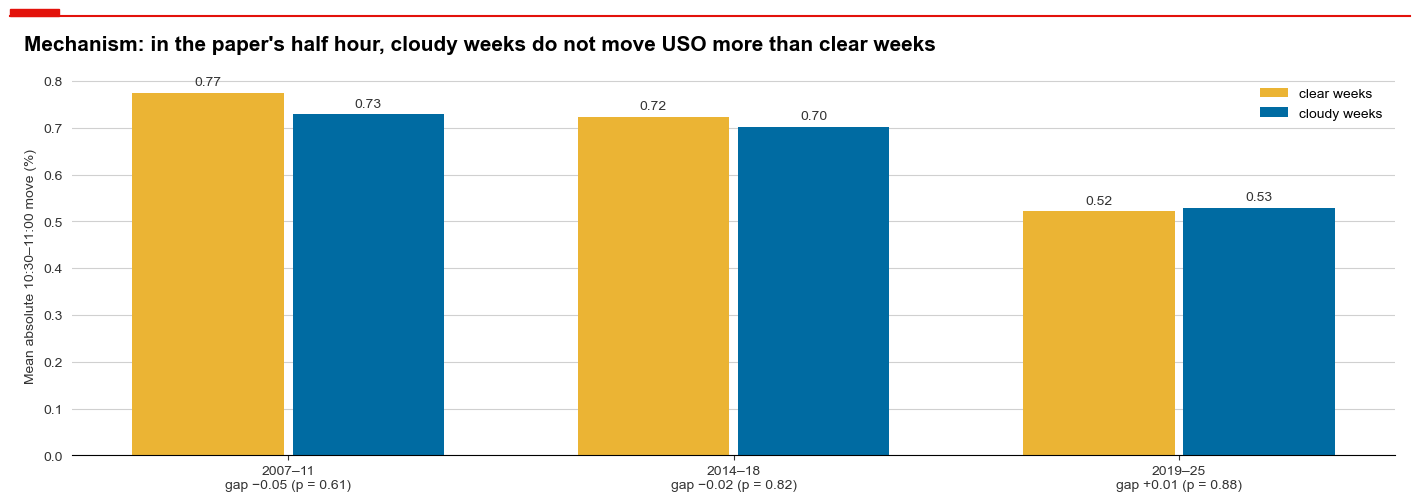

In [44]:
fig, ax = plt.subplots(figsize=(14, 4.8))
positions = np.arange(len(mechanism))
for shift, name, color in [(-0.18, "clear", CLEAR), (0.18, "cloudy", CLOUDY)]:
    values = mechanism[f"{name} |move| (%)"]
    ax.bar(positions + shift, values, width=0.34, color=color, label=f"{name} weeks")
    for x, value in zip(positions + shift, values):
        ax.text(x, value + 0.01, f"{value:.2f}", ha="center", va="bottom", fontsize=10, color=DARK)
ax.set_xticks(positions, [minus_sign(f"{period}\ngap {row['cloudy − clear']:+.2f} (p = {row['p']:.2f})")
                          for period, row in mechanism.iterrows()])
ax.set_ylabel("Mean absolute 10:30–11:00 move (%)")
ax.legend(loc="upper right")
show("Mechanism: in the paper's half hour, cloudy weeks do not move USO more than clear weeks")

## c.4 The straddle

In [45]:
options = pd.read_csv(os.path.join(RAW, "optionmetrics_uso_std_30d.csv"), parse_dates=["date"])
uso = pd.read_csv(os.path.join(RAW, "optionmetrics_uso_prices.csv"), parse_dates=["date"], index_col="date")
STRADDLE_PERIODS = {"2007–11": PERIODS["2007–11"], "2014–18": PERIODS["2014–18"],
                    "2019–24": ("2019-01-01", "2024-12-31")}  # OptionMetrics ends in December 2024


def straddle_costs(days, trading_days):
    '''Expected one-day move (fraction of the price) on each date, from at-the-money options of `days` days:
    from the premiums ("cost") and from the implied volatility ("cost_iv").'''
    table = options[(options["days"] == days) & (options["premium"] > 0)]
    wide = table.pivot(index="date", columns="cp_flag", values=["premium", "forward_price", "impl_volatility"])
    straddle = (wide["premium"]["C"] + wide["premium"]["P"]) / wide["forward_price"]["C"]
    return pd.DataFrame({"cost": straddle / np.sqrt(trading_days),
                         "cost_iv": wide["impl_volatility"].mean(axis=1) / np.sqrt(252)}).dropna()


def trade_table(cost, payoff):
    '''One row per release: cost (%) on the trading day before, payoff (%) on the release day, and profit.'''
    table = reports[reports["release"].isin(uso.index)].copy()
    position = uso.index.get_indexer(table["release"])
    table, position = table[position > 0], position[position > 0]  # we need a trading day before
    table["entry"] = uso.index[position - 1]
    table["cost"] = 100 * cost.reindex(table["entry"]).to_numpy()
    table["payoff"] = payoff.reindex(table["release"]).to_numpy()
    table["profit"] = table["payoff"] - table["cost"]
    return table.dropna(subset=["cost", "payoff"])


# The replication's cloudy label of every week: its own sample and threshold per period
REPLICATION_LABELS = pd.concat([weeks_of(period)[["release", "threshold", "cloudy"]] for period in PERIODS])


def by_period(trades, periods=STRADDLE_PERIODS):
    '''Trades of each period with the replication's cloudy label of their week; unlabelled weeks drop out.'''
    labelled = trades.merge(REPLICATION_LABELS, on="release")
    return {period: labelled[labelled["release"].between(*span)] for period, span in periods.items()}


def strategy_rows(samples):
    '''Trades, mean profit, t-statistic and hit rate per strategy and period, and Cloudy minus Always.'''
    rows = {}
    for period, sample in samples.items():
        cloudy = sample["cloudy"] == 1
        draws = bootstrap_means(sample["profit"], cloudy)
        for name, chosen in {"Always": cloudy | ~cloudy, "Cloudy only": cloudy, "Clear only": ~cloudy}.items():
            profit = sample.loc[chosen, "profit"]
            rows[(period, name)] = {"trades": len(profit), "mean profit (%)": profit.mean(),
                                    "t": profit.mean() / (profit.std() / np.sqrt(len(profit))),
                                    "hit rate": (profit > 0).mean()}
        gap = rows[(period, "Cloudy only")]["mean profit (%)"] - rows[(period, "Always")]["mean profit (%)"]
        rows[(period, "Cloudy only")].update({"cloudy − always": gap,
                                              "p": p_value(draws["cloudy"] - draws["all"])})
    return pd.DataFrame(rows).T.astype({"trades": int})


costs_30 = straddle_costs(30, trading_days=21)
daily_payoff = 100 * uso["return"].abs()  # % of the price
main = by_period(trade_table(costs_30["cost"], daily_payoff))
main_table = strategy_rows(main)
main_table

trades  mean profit (%)      t  hit rate  \
2007–11 Always          242           -0.023 -0.240     0.405   
        Cloudy only      58           -0.042 -0.211     0.379   
        Clear only      184           -0.017 -0.155     0.413   
2014–18 Always          261            0.160  1.858     0.479   
        Cloudy only      65            0.479  2.502     0.508   
        Clear only      196            0.053  0.568     0.469   
2019–24 Always          311           -0.107 -1.267     0.376   
        Cloudy only      77            0.059  0.267     0.442   
        Clear only      234           -0.162 -1.896     0.355   

                     cloudy − always     p  
2007–11 Always                   NaN   NaN  
        Cloudy only           -0.019 0.898  
        Clear only               NaN   NaN  
2014–18 Always                   NaN   NaN  
        Cloudy only            0.320 0.042  
        Clear only               NaN   NaN  
2019–24 Always                   NaN   NaN  
        Cloudy only            0.167 0.361  
        Clear only               NaN   NaN

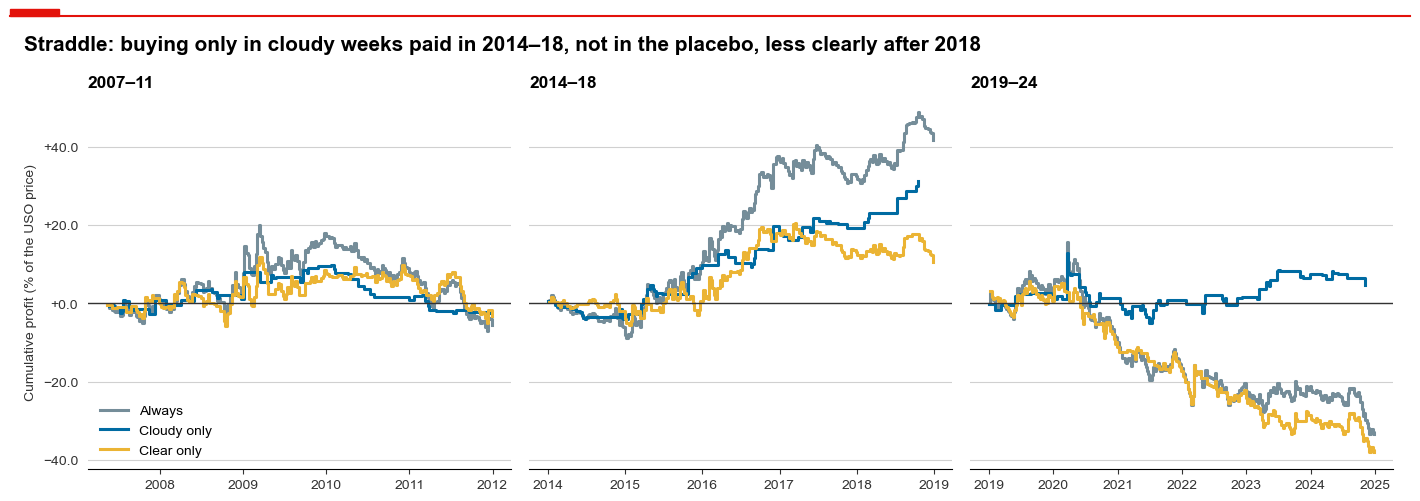

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
for ax, (period, sample) in zip(axes, main.items()):
    cloudy = sample["cloudy"] == 1
    for name, chosen, color in [("Always", cloudy | ~cloudy, ALWAYS), ("Cloudy only", cloudy, CLOUDY),
                                ("Clear only", ~cloudy, CLEAR)]:
        path = sample.loc[chosen].set_index("release")["profit"].cumsum()
        ax.step(path.index, path, where="post", color=color, lw=2.2, label=name)
    ax.axhline(0, color=DARK, lw=1)
    ax.set_title(period, fontsize=12.5)
    ax.yaxis.set_major_formatter(SIGNED)
axes[0].set_ylabel("Cumulative profit (% of the USO price)")
axes[0].legend(loc="lower left")
show("Straddle: buying only in cloudy weeks paid in 2014–18, not in the placebo, less clearly after 2018",
     save="c2_cumulative_profit")

## c.5 Robustness, one change at a time

In [47]:
costs_10 = straddle_costs(10, trading_days=7)
intraday_payoff = reports.set_index("release")["ret"].abs()  # 10:30-11:00, in %
FROM_2014 = {period: span for period, span in STRADDLE_PERIODS.items() if period != "2007–11"}

robustness = {
    "Main: 30-day premiums, daily payoff": main,
    "Cost from implied volatility": by_period(trade_table(costs_30["cost_iv"], daily_payoff)),
    "10-day options (from 2014)": by_period(trade_table(costs_10["cost"], daily_payoff), FROM_2014),
    "Intraday payoff (sensitivity only)": by_period(trade_table(costs_30["cost"] * np.sqrt(30 / 390),
                                                                intraday_payoff)),
}
robustness_tables = {name: strategy_rows(samples) for name, samples in robustness.items()}

summary = {}
for name, table in robustness_tables.items():
    for period in table.index.get_level_values(0).unique():
        summary[(name, period)] = {
            "trades": table.loc[(period, "Always"), "trades"],
            "Always (%)": table.loc[(period, "Always"), "mean profit (%)"],
            "Cloudy only (%)": table.loc[(period, "Cloudy only"), "mean profit (%)"],
            "Clear only (%)": table.loc[(period, "Clear only"), "mean profit (%)"],
            "cloudy − always": table.loc[(period, "Cloudy only"), "cloudy − always"],
            "p": table.loc[(period, "Cloudy only"), "p"]}
summary = pd.DataFrame(summary).T.astype({"trades": int})
summary

trades  Always (%)  \
Main: 30-day premiums, daily payoff 2007–11     242      -0.023   
                                    2014–18     261       0.160   
                                    2019–24     311      -0.107   
Cost from implied volatility        2007–11     242      -0.551   
                                    2014–18     261      -0.266   
                                    2019–24     311      -0.608   
10-day options (from 2014)          2014–18     261       0.127   
                                    2019–24     311      -0.134   
Intraday payoff (sensitivity only)  2007–11     242       0.198   
                                    2014–18     261       0.269   
                                    2019–24     311       0.018   

                                             Cloudy only (%)  Clear only (%)  \
Main: 30-day premiums, daily payoff 2007–11           -0.042          -0.017   
                                    2014–18            0.479           0.053   
                                    2019–24            0.059          -0.162   
Cost from implied volatility        2007–11           -0.525          -0.559   
                                    2014–18            0.077          -0.380   
                                    2019–24           -0.463          -0.656   
10-day options (from 2014)          2014–18            0.458           0.017   
                                    2019–24            0.025          -0.186   
Intraday payoff (sensitivity only)  2007–11            0.168           0.207   
                                    2014–18            0.276           0.267   
                                    2019–24            0.001           0.024   

                                             cloudy − always     p  
Main: 30-day premiums, daily payoff 2007–11           -0.019 0.898  
                                    2014–18            0.320 0.042  
                                    2019–24            0.167 0.361  
Cost from implied volatility        2007–11            0.025 0.894  
                                    2014–18            0.343 0.026  
                                    2019–24            0.145 0.422  
10-day options (from 2014)          2014–18            0.331 0.033  
                                    2019–24            0.159 0.386  
Intraday payoff (sensitivity only)  2007–11           -0.029 0.671  
                                    2014–18            0.007 0.916  
                                    2019–24           -0.017 0.676

## c.6 Where the 2014–18 profit comes from (diagnostic, added after seeing the results)
Not a new rule: we split the main profit into payoff and cost, and look at each year of 2014–18.

In [48]:
split = pd.concat({period: sample.groupby(sample["cloudy"].map({0: "clear", 1: "cloudy"}))[["payoff", "cost",
                                                                                               "profit"]].mean()
                   for period, sample in main.items()})
split

payoff  cost  profit
        cloudy                      
2007–11 clear    2.038 2.056  -0.017
        cloudy   1.796 1.838  -0.042
2014–18 clear    1.701 1.648   0.053
        cloudy   2.014 1.534   0.479
2019–24 clear    1.714 1.877  -0.162
        cloudy   2.041 1.981   0.059

In [49]:
baseline_trades = main["2014–18"]
year_gap = {}
for year, sample in baseline_trades.groupby(baseline_trades["release"].dt.year):
    cloudy = sample["cloudy"] == 1
    year_gap[year] = {"cloudy weeks": cloudy.sum(), "Always (%)": sample["profit"].mean(),
                      "Cloudy only (%)": sample.loc[cloudy, "profit"].mean()}
year_gap = pd.DataFrame(year_gap).T.astype({"cloudy weeks": int})
year_gap["cloudy − always"] = year_gap["Cloudy only (%)"] - year_gap["Always (%)"]
year_gap

,cloudy weeks,Always (%),Cloudy only (%),cloudy − always
2014,17,-0.152,-0.235,-0.083
2015,15,0.356,0.924,0.568
2016,12,0.501,0.718,0.217
2017,12,-0.079,0.060,0.139
2018,9,0.177,1.328,1.151


## c.7 Verdict

* **The mechanism does not show up in the size of the move.** In the paper's window, 10:30 to 11:00 a.m.,
  USO moves as much in clear weeks as in cloudy weeks, in every period (gaps of −0.05 to +0.01 percentage
  points, p ≥ 0.6). The paper's result is about the *direction* of the reaction to the surprise, which a
  straddle does not use.
* **Over the whole release day, cloudy weeks paid in 2014–18.** Buying the straddle only in cloudy weeks
  earned 0.48% of the USO price per trade, against 0.16% for every week: +0.32 points, p = 0.04. Cloudy weeks
  had bigger moves (2.01% against 1.70%) and slightly cheaper options. The gap holds with the cost from
  implied volatility (+0.34, p = 0.03) and with 10-day options (+0.33, p = 0.03). It comes from 2015, 2016 and
  2018, not from one year.
* **Per trade, not in total.** In 2014–18 Cloudy only earns more per trade, but trades a quarter as often, so
  Always ends higher in total (chart in Section c.4). In 2019–24 Cloudy only also wins in total, because Always
  loses money there.
* **No gain in the placebo, and a weaker one after 2018.** In 2007–11, with few satellites, Cloudy only is a
  little worse than Always (−0.02, p = 0.90). In 2019–24 it is better but not significantly (+0.17, p = 0.36).
  The pattern of the paper's story (nothing before satellites, a gain once satellites watch clear weeks) is
  there, but it is significant in only one of three periods.
* **Not in the paper's half hour.** With the intraday payoff the gap disappears (+0.01 in 2014–18, p = 0.92).
  So the extra move in cloudy weeks happens on the release day but outside 10:30 to 11:00, and the paper's
  mechanism does not explain it.
* **An upper bound.** Our cost has no bid-ask spread and no event premium, and the straddle profit is
  simplified. Real profits are lower for every strategy. An extra cost that is the same for every trade lowers
  all strategies alike and leaves the gap Cloudy minus Always unchanged.

**Risks.** One significant period out of three, after several variants, can be luck. Cloudy weeks are seasonal
(most frequent in May), so the gap can partly be a seasonal pattern in oil volatility. 58 to 77 cloudy trades per
period is a small sample, and the result depends on a few large moves.

## c.8 Robustness check added after seeing results: release time

Like the replication, we measure every report from 10:30 to 11:00 a.m. But a report pushed off its Wednesday by a
holiday comes out on another day, often at another time, and then our window can miss it. Neither the
replication's code nor EIA's archive page gives release **times**, only dates, so we cannot use the 30 minutes
after each actual release. We run two versions instead.

**Rules (fixed before running):**
* **Main version: Wednesday only.** We keep the releases on a Wednesday, which we take to be at 10:30 as the
  replication does, and drop the weeks released on any other day.
* **Sensitivity: 11:00 assumed.** We keep all weeks and use 11:00 to 11:30 for the weeks released on another day.
  **11:00 is an assumption** (EIA's usual time for a report delayed by a holiday), not an observed time.
* Each week keeps the cloudy label it has in the original results, so only the window and the set of weeks
  change. In the intraday payoff the cost stays the daily cost × √(30/390); only the payoff window moves.

We rerun the mechanism check (Section c.3) and the intraday payoff (Section c.5) for the same periods as before.

In [50]:
off_wednesday = reports.loc[reports["release"].between("2007-01-01", "2025-12-31")
                            & (reports["release"].dt.dayofweek != 2), "release"]
print(f"{len(off_wednesday)} releases from 2007 to 2025 are not on a Wednesday "
      f"({off_wednesday.dt.day_name().value_counts().to_dict()}):")
for year, days in off_wednesday.groupby(off_wednesday.dt.year):
    print(year, ", ".join(days.dt.strftime("%a %d %b")))

145 releases from 2007 to 2025 are not on a Wednesday ({'Thursday': 131, 'Friday': 12, 'Monday': 2}):
2007 Thu 04 Jan, Thu 18 Jan, Thu 22 Feb, Thu 31 May, Thu 05 Jul, Thu 06 Sep, Thu 11 Oct, Thu 15 Nov, Fri 28 Dec
2008 Fri 04 Jan, Thu 24 Jan, Thu 21 Feb, Thu 29 May, Thu 04 Sep, Thu 16 Oct, Thu 13 Nov
2009 Thu 22 Jan, Thu 19 Feb, Thu 28 May, Thu 10 Sep, Thu 15 Oct, Thu 12 Nov
2010 Thu 21 Jan, Thu 18 Feb, Thu 03 Jun, Thu 08 Jul, Thu 09 Sep, Thu 14 Oct
2011 Thu 20 Jan, Thu 24 Feb, Thu 02 Jun, Thu 07 Jul, Thu 08 Sep, Thu 13 Oct, Thu 29 Dec
2012 Thu 05 Jan, Thu 19 Jan, Thu 23 Feb, Thu 31 May, Thu 05 Jul, Thu 06 Sep, Thu 11 Oct, Thu 01 Nov, Thu 15 Nov, Fri 28 Dec
2013 Fri 04 Jan, Thu 24 Jan, Thu 21 Feb, Thu 30 May, Thu 05 Sep, Mon 21 Oct, Thu 14 Nov, Fri 27 Dec
2014 Fri 03 Jan, Thu 23 Jan, Thu 20 Feb, Thu 29 May, Thu 04 Sep, Thu 16 Oct, Thu 13 Nov
2015 Thu 22 Jan, Thu 19 Feb, Thu 28 May, Thu 10 Sep, Thu 15 Oct, Thu 12 Nov
2016 Thu 21 Jan, Thu 18 Feb, Thu 02 Jun, Thu 07 Jul, Thu 08 Sep, Thu 1

In [51]:
late_returns = window_returns("11:00", "11:30")  # the assumed window for releases off Wednesday


def on_wednesday(sample):
    '''Only the weeks whose report came out on a Wednesday.'''
    return sample[sample["release"].dt.dayofweek == 2]


def late_move(sample):
    '''Mechanism sample with the 11:00-11:30 return for the weeks released off Wednesday.'''
    off = sample["release"].dt.dayofweek != 2
    ret = sample["ret"].where(~off, sample["release"].map(late_returns))
    return sample.assign(ret=ret).dropna(subset=["ret"])


def late_payoff(sample):
    '''Intraday payoff sample with the absolute 11:00-11:30 move for the weeks released off Wednesday.'''
    off = sample["release"].dt.dayofweek != 2
    payoff = sample["payoff"].where(~off, sample["release"].map(late_returns).abs())
    return sample.assign(payoff=payoff, profit=payoff - sample["cost"]).dropna(subset=["profit"])


def mechanism_gap(sample):
    '''Cloudy and clear weeks, mean absolute move of cloudy minus clear weeks, and its bootstrap p-value.'''
    move, cloudy = sample["ret"].abs(), sample["cloudy"] == 1
    draws = bootstrap_means(move, cloudy)
    return {"cloudy weeks": cloudy.sum(), "clear weeks": (~cloudy).sum(),
            "gap": move[cloudy].mean() - move[~cloudy].mean(), "p": p_value(draws["cloudy"] - draws["clear"])}


def payoff_gap(sample):
    '''Cloudy and clear trades, mean profit of Cloudy only minus Always, and its bootstrap p-value.'''
    profit, cloudy = sample["profit"], sample["cloudy"] == 1
    draws = bootstrap_means(profit, cloudy)
    return {"cloudy weeks": cloudy.sum(), "clear weeks": (~cloudy).sum(),
            "gap": profit[cloudy].mean() - profit.mean(), "p": p_value(draws["cloudy"] - draws["all"])}


CHECKS = {  # analysis: (samples of each period, version that moves the window, statistic)
    "Mechanism: cloudy − clear |move| (%)": ({period: weeks_of(period) for period in PERIODS}, late_move,
                                             mechanism_gap),
    "Intraday payoff: cloudy − always (%)": (robustness["Intraday payoff (sensitivity only)"], late_payoff,
                                             payoff_gap),
}
release_time = {}
for analysis, (samples, move_window, statistic) in CHECKS.items():
    for period, sample in samples.items():
        versions = {"Original": sample, "Wednesday 10:30 only": on_wednesday(sample),
                    "All weeks, 11:00 assumed off Wednesday": move_window(sample)}
        for version, data in versions.items():
            for name, value in statistic(data).items():
                release_time.setdefault((version, name), {})[(analysis, period)] = value
release_time = pd.DataFrame(release_time)
for version in release_time.columns.get_level_values(0).unique():
    release_time[(version, "cloudy weeks")] = release_time[(version, "cloudy weeks")].astype(int)
    release_time[(version, "clear weeks")] = release_time[(version, "clear weeks")].astype(int)
release_time

Original                     \
                                             cloudy weeks clear weeks    gap   
Mechanism: cloudy − clear |move| (%) 2007–11           65         196 -0.045   
                                     2014–18           65         196 -0.023   
                                     2019–25           87         259  0.008   
Intraday payoff: cloudy − always (%) 2007–11           58         184 -0.029   
                                     2014–18           65         196  0.007   
                                     2019–24           77         234 -0.017   

                                                   Wednesday 10:30 only  \
                                                 p         cloudy weeks   
Mechanism: cloudy − clear |move| (%) 2007–11 0.614                   52   
                                     2014–18 0.818                   53   
                                     2019–25 0.883                   74   
Intraday payoff: cloudy − always (%) 2007–11 0.671                   46   
                                     2014–18 0.916                   53   
                                     2019–24 0.676                   65   

                                                                       \
                                             clear weeks    gap     p   
Mechanism: cloudy − clear |move| (%) 2007–11         174 -0.097 0.359   
                                     2014–18         170  0.010 0.951   
                                     2019–25         222  0.020 0.812   
Intraday payoff: cloudy − always (%) 2007–11         164 -0.063 0.451   
                                     2014–18         170  0.021 0.826   
                                     2019–24         200 -0.001 0.966   

                                             All weeks, 11:00 assumed off Wednesday  \
                                                                       cloudy weeks   
Mechanism: cloudy − clear |move| (%) 2007–11                                     65   
                                     2014–18                                     65   
                                     2019–25                                     87   
Intraday payoff: cloudy − always (%) 2007–11                                     58   
                                     2014–18                                     65   
                                     2019–24                                     77   

                                                                       
                                             clear weeks    gap     p  
Mechanism: cloudy − clear |move| (%) 2007–11         196 -0.132 0.149  
                                     2014–18         196  0.040 0.688  
                                     2019–25         259  0.042 0.521  
Intraday payoff: cloudy − always (%) 2007–11         184 -0.068 0.335  
                                     2014–18         196  0.054 0.449  
                                     2019–24         234  0.021 0.689

**Comments – release time**
* **145 of 990 reports from 2007 to 2025 are not on a Wednesday:** 131 on a Thursday, 12 on a Friday (11 around
  Christmas and New Year, 1 in the week of the 2021 inauguration) and 2 on a Monday (21 October 2013, after the government shutdown, and 29 December 2025).
* **Wednesday only (main version):** we lose 12 or 13 cloudy and 20 to 37 clear weeks per period. The mechanism
  gap stays close to zero in every period (−0.10, +0.01, +0.02; smallest p 0.36), and so does the intraday payoff gap
  (−0.06, +0.02, 0.00; smallest p 0.45).
* **11:00 assumed (sensitivity):** no week is lost. The gaps move a little (mechanism −0.13, +0.04, +0.04;
  intraday payoff −0.07, +0.05, +0.02) but none is significant (smallest p 0.15).
* **Our conclusion holds:** in the half hour after the report, cloudy weeks do not move USO more than clear
  weeks, whichever way we treat the holiday weeks.

## c.9 Robustness check added after seeing results: season

Cloudy weeks are not spread evenly over the year, and oil volatility has its own seasons. So the gap could be a
calendar pattern rather than clouds. We compare cloudy and clear weeks **within the same calendar month**.

**Rule (fixed before running):** per period, main version, we regress the profit per trade on the Cloudy dummy
and one dummy per calendar month of the release. Same inference as above: 5,000 bootstrap draws of weeks,
seed 20598, two-sided p-value. We get the month dummies by subtracting each month's mean from the profit and
from the dummy (the Frisch–Waugh theorem gives the same coefficient as the full regression), which also works in
a bootstrap draw that misses a month. A month without cloudy trades adds nothing to the estimate.

Without month dummies the regression gives Cloudy minus Clear, so we show that next to the new number. The
first column repeats Cloudy minus Always from Section 4.

In [52]:
def cloudy_slope(profit, cloudy, month=None):
    '''OLS coefficient of the cloudy dummy, with calendar month dummies if `month` (1 to 12) is given.'''
    if month is not None:
        counts = np.maximum(np.bincount(month, minlength=13), 1)
        profit = profit - (np.bincount(month, weights=profit, minlength=13) / counts)[month]
        cloudy = cloudy - (np.bincount(month, weights=cloudy, minlength=13) / counts)[month]
    else:
        profit, cloudy = profit - profit.mean(), cloudy - cloudy.mean()
    return (cloudy * profit).sum() / (cloudy * cloudy).sum()


def bootstrap_slope(sample, with_months):
    '''Estimate and bootstrap p-value of the cloudy coefficient, drawing weeks with replacement.'''
    profit = sample["profit"].to_numpy(float)
    cloudy = sample["cloudy"].to_numpy(float)
    month = sample["release"].dt.month.to_numpy() if with_months else None
    estimate = cloudy_slope(profit, cloudy, month)
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(BOOT_DRAWS):
        rows = rng.integers(0, len(profit), len(profit))
        draws.append(cloudy_slope(profit[rows], cloudy[rows], None if month is None else month[rows]))
    return estimate, p_value(np.array(draws))


season = {}
for period, sample in main.items():
    old_gap = main_table.loc[(period, "Cloudy only")]
    no_months = bootstrap_slope(sample, with_months=False)
    months = bootstrap_slope(sample, with_months=True)
    season[period] = {"cloudy − always (Section c.4)": old_gap["cloudy − always"], "p (Section c.4)": old_gap["p"],
                      "cloudy − clear, no months": no_months[0], "p, no months": no_months[1],
                      "cloudy − clear, month dummies": months[0], "p, month dummies": months[1]}
season = pd.DataFrame(season).T
season

,cloudy − always (Section c.4),p (Section c.4),"cloudy − clear, no months","p, no months","cloudy − clear, month dummies","p, month dummies"
2007–11,-0.019,0.898,-0.025,0.898,-0.072,0.758
2014–18,0.320,0.042,0.426,0.042,0.478,0.024
2019–24,0.167,0.361,0.222,0.361,0.168,0.476


Cloudy trades per calendar month, per period:

In [53]:
cloudy_months = pd.DataFrame({period: sample.loc[sample["cloudy"] == 1, "release"].dt.month.value_counts()
                              for period, sample in main.items()}).reindex(range(1, 13)).fillna(0).astype(int)
cloudy_months.index = [pd.Timestamp(2001, month, 1).strftime("%b") for month in cloudy_months.index]
cloudy_months.T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
2007–11,4,3,4,4,10,4,9,4,8,2,2,4
2014–18,3,6,5,5,8,8,3,7,5,5,4,6
2019–24,6,4,10,4,12,8,10,6,7,1,5,4


**Comments – season**
* **Not a calendar effect.** Within the same calendar month the 2014–18 gap is larger, not smaller: +0.48 points
  per trade (p = 0.02), against +0.43 for Cloudy minus Clear without month dummies. In 2007–11 (−0.07, p = 0.76)
  and 2019–24 (+0.17, p = 0.48) the month dummies do not change our verdict either.
* **Cloudy weeks are not mostly in winter.** They come in every month, most often in May (and June in 2014–18),
  as the replication found. December to February hold only 11 to 15 of the 58 to 77 cloudy trades per period.
* The p-values of the first two columns are equal by construction: Cloudy minus Always is Cloudy minus Clear
  times the share of clear weeks, so the two have the same sign in every bootstrap draw.

## c.10 All robustness checks of 2014–18 in one chart (added after seeing results)
The gap of 2014–18, the one significant period, under every check of Sections c.5, c.8 and c.9, with 95% bootstrap
intervals from the same draws as their p-values. Each row says which difference it shows.

In [54]:
def slope_with_draws(sample, with_months):
    """Cloudy coefficient (cloudy minus clear) and its bootstrap draws, as in Section c.9."""
    profit = sample["profit"].to_numpy(float)
    cloudy = sample["cloudy"].to_numpy(float)
    month = sample["release"].dt.month.to_numpy() if with_months else None
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(BOOT_DRAWS):
        rows = rng.integers(0, len(profit), len(profit))
        draws.append(cloudy_slope(profit[rows], cloudy[rows], None if month is None else month[rows]))
    return cloudy_slope(profit, cloudy, month), np.array(draws)


def gap_with_draws(sample):
    """Cloudy only minus Always and its bootstrap draws, as in Sections c.4 and c.5."""
    cloudy = sample["cloudy"] == 1
    draws = bootstrap_means(sample["profit"], cloudy)
    return sample.loc[cloudy, "profit"].mean() - sample["profit"].mean(), draws["cloudy"] - draws["all"]


PERIOD = "2014–18"
intraday = robustness["Intraday payoff (sensitivity only)"][PERIOD]
CHECKS_2014 = {  # row label: (group, estimate and draws)
    "Main: 30-day premiums": ("Daily straddle, cloudy − always", gap_with_draws(main[PERIOD])),
    "Cost from implied volatility": ("Daily straddle, cloudy − always",
                                     gap_with_draws(robustness["Cost from implied volatility"][PERIOD])),
    "10-day options": ("Daily straddle, cloudy − always",
                       gap_with_draws(robustness["10-day options (from 2014)"][PERIOD])),
    "No month dummies": ("Daily straddle, cloudy − clear", slope_with_draws(main[PERIOD], False)),
    "Calendar month dummies": ("Daily straddle, cloudy − clear", slope_with_draws(main[PERIOD], True)),
    "10:30–11:00, all weeks": ("Half-hour payoff, cloudy − always", gap_with_draws(intraday)),
    "Wednesday 10:30 only": ("Half-hour payoff, cloudy − always", gap_with_draws(on_wednesday(intraday))),
    "11:00 assumed off Wednesday": ("Half-hour payoff, cloudy − always", gap_with_draws(late_payoff(intraday))),
}
forest = pd.DataFrame({label: {"group": group, "estimate": estimate, "low": np.percentile(draws, 2.5),
                               "high": np.percentile(draws, 97.5), "p": p_value(draws)}
                       for label, (group, (estimate, draws)) in CHECKS_2014.items()}).T
forest

,group,estimate,low,high,p
Main: 30-day premiums,"Daily straddle, cloudy − always",0.320,0.016,0.653,0.042
Cost from implied volatility,"Daily straddle, cloudy − always",0.343,0.044,0.668,0.026
10-day options,"Daily straddle, cloudy − always",0.331,0.031,0.657,0.033
No month dummies,"Daily straddle, cloudy − clear",0.426,0.021,0.860,0.042
Calendar month dummies,"Daily straddle, cloudy − clear",0.478,0.065,0.932,0.024
"10:30–11:00, all weeks","Half-hour payoff, cloudy − always",0.007,-0.125,0.155,0.916
Wednesday 10:30 only,"Half-hour payoff, cloudy − always",0.021,-0.132,0.191,0.826
11:00 assumed off Wednesday,"Half-hour payoff, cloudy − always",0.054,-0.086,0.204,0.449


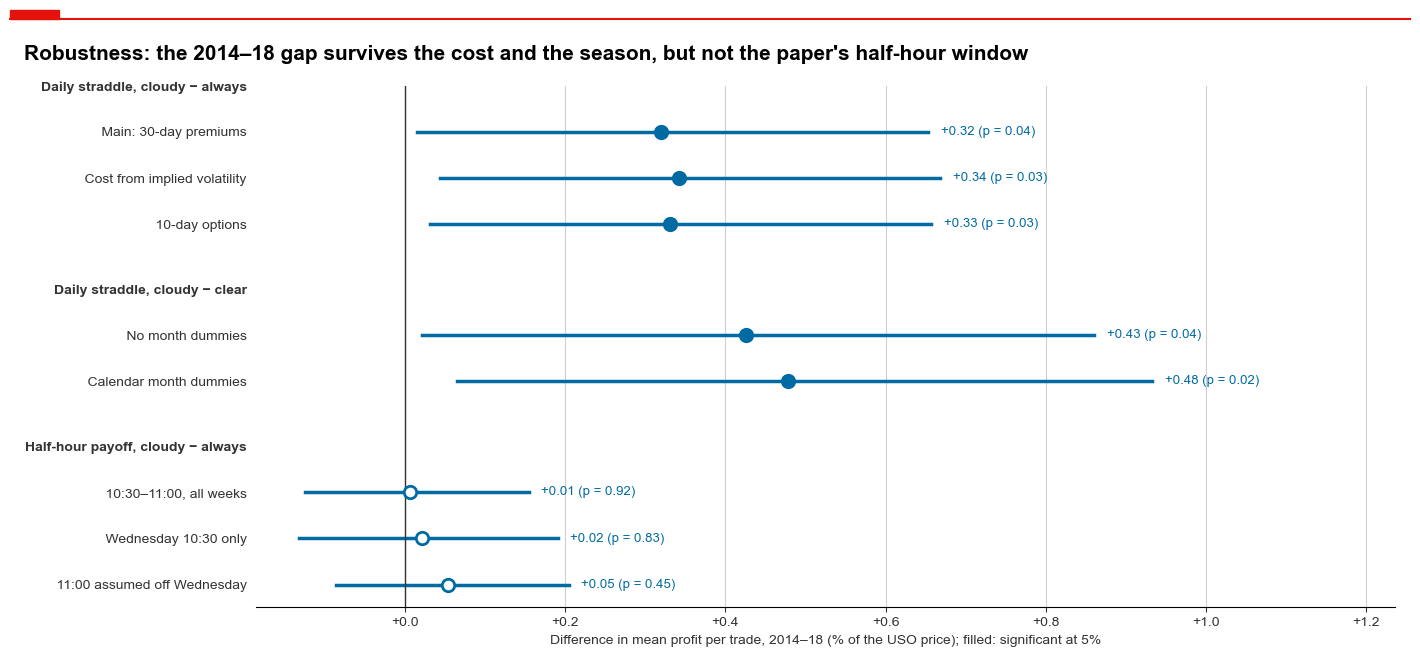

In [55]:
fig, ax = plt.subplots(figsize=(14, 6.3))
positions, labels, y = [], [], 0
for group, rows in forest.groupby("group", sort=False):
    labels.append(group)
    positions.append(y)
    header_y = y
    y -= 1
    for label, row in rows.iterrows():
        significant = row["p"] < 0.05
        ax.plot([row["low"], row["high"]], [y, y], color=GAP, lw=2.5)
        ax.scatter(row["estimate"], y, s=80, zorder=3, color=GAP if significant else "white", edgecolor=GAP, lw=2)
        annotate(ax, minus_sign(f"{row['estimate']:+.2f} (p = {row['p']:.2f})"), (row["high"], y), color=GAP)
        positions.append(y)
        labels.append("    " + label)
        y -= 1
    y -= 0.4
ax.set_yticks(positions, labels)
for tick, label in zip(ax.get_yticklabels(), labels):
    if not label.startswith(" "):
        tick.set_fontweight("bold")
ax.axvline(0, color=DARK, lw=1)
ax.grid(False, axis="y")
ax.grid(True, axis="x", color=GRID)
ax.set_xlabel("Difference in mean profit per trade, 2014–18 (% of the USO price); filled: significant at 5%")
ax.xaxis.set_major_formatter(SIGNED)
ax.set_xlim(right=ax.get_xlim()[1] + 0.25)
show("Robustness: the 2014–18 gap survives the cost and the season, but not the paper's half-hour window",
     save="c3_robustness")

# (d) Limitations

**What we chose after seeing results**
* **The improved shadow index was chosen after seeing results.** Each of its three changes has a reason that does
  not depend on the correlation, but we tried about 25 variants (`Satellite_experiments.ipynb`), and moving the
  circles 5 m south alone gives −0.72. The baseline, with rules fixed in advance, gives −0.40.
* **The robustness checks of the straddle were added after seeing results:** the profit diagnostic (c.6), the
  release time (c.8), the season (c.9) and the summary chart (c.10). The main rules (c.2) were fixed before.

**Part (a), the replication**
* In the paper's main window our 2014–18 gap is about a third of the paper's (−0.16, p = 0.25, against −0.46); it
  is significant only in the wider windows. After 2018 it is gone.
* We use USO, an oil fund, instead of WTI futures, and the paper's Internet Appendix only in part: **the macro
  checks of Table IA-1 (stock, energy and industrial commodity indices, Baltic Dry Index) were not replicated,
  because the data are not available to us.** Its inventory panel (the size of the surprise) is in Task #1.
* **The fixed-airport check shows 18 of 19 specifications on this machine:** it needs
  `data/out/daily_cloudiness.csv` from `pipeline/03_cloudiness.py` (a NOAA ISD download of about 400–650 MB), which
  we have not run here. The comments of Task #4, written on a machine with that file, count 19.
* EIA's archive gives release dates but not times: 145 of 990 reports (2007–25) were not on a Wednesday. NOAA's
  weather data end in August 2025.

**Part (b), the shadow index**
* Winters only (sun below 45°), 67 cloud free dates over 2017–24, an assumed tank height of 15 m (18 m and 12 m
  give −0.64 and −0.67) and a tank map from OpenStreetMap.
* It tracks the level of Cushing stocks, not the weekly change (z −1.8), so it gives no edge on the EIA number.

**Part (c), the cloud straddle**
* **Only 1 of 3 straddle periods is significant:** 2014–18 (+0.32 per trade, p = 0.04); 2007–11 −0.02 (p = 0.90)
  and 2019–24 +0.17 (p = 0.36) are not.
* **The profits are an upper bound:** the cost has no bid-ask spread and no event premium (a straddle bought the
  day before an EIA report costs more than on an average day), and the straddle profit is simplified (held one
  day, valued by the day's move only).
* The 2014–18 gain is not in the paper's half hour (+0.01 with the 10:30–11:00 payoff), so the paper's mechanism
  does not explain it; it rests on 65 cloudy trades and a few large moves.
* The straddle asks about the size of the move, the paper about the slope of the reaction (Section c.1): our result
  is not a test of the paper's mechanism.

# Verdict
* **(a)** We find the paper's cloudy-week reaction in 2014–18, but slower and smaller in its main window, and not
  after 2018.
* **(b)** A free satellite index of Cushing is possible and tracks the level of stocks, but not the weekly change
  that the EIA report reveals: no edge.
* **(c)** Buying the straddle only in cloudy weeks paid more per trade than buying it every week in 2014–18, but not
  in the placebo period and not significantly after 2018, and only as an upper bound.

## References
* Mukherjee, A., Panayotov, G. and Shon, J. (2021), Eye in the sky: Private satellites and government macro data, *Journal of Financial Economics* 141, 234–254.
* Newey, W. K. and West, K. D. (1987), A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix, *Econometrica* 55, 703–708.
* LSEG Tick History: one-minute bars of USO.P (United States Oil Fund, NYSE Arca), 2007–2026, retrieved November 2026.
* U.S. Energy Information Administration: Weekly Petroleum Status Report (crude oil stocks excluding SPR, archive of release dates), downloaded November 2026.
* NOAA National Centers for Environmental Information, Integrated Surface Database (hourly sky cover); National Hurricane Center, HURDAT2 best tracks.
* Cboe crude oil volatility index (OVX), via FRED, Federal Reserve Bank of St. Louis.
* European Space Agency, Copernicus Sentinel 2 Level 2A images, via Element 84 Earth Search (AWS).
* OpenStreetMap contributors, storage tank outlines (Overpass API).
* U.S. Energy Information Administration: Weekly Cushing, OK ending stocks of crude oil.
* OptionMetrics IvyDB (via WRDS): standardised options and prices of USO.